# Pangeo-Fish による魚類の位置推定：海底地形と潮汐を加える

**放流から再捕までのあいだ、魚はどこを移動していたのでしょうか？** このノートブックは「[Pangeo-Fish による魚類の位置推定](pangeo-fish.ipynb)」の続きです。水温と音響テレメトリーの受信記録に加えて、海底地形と潮汐の情報も使い、各時刻に魚がいた可能性のある場所を推定します。科学的な背景や理論の解説は、[日本語の科学・技術解説を読むために](science/00_guide.md)にまとめています。

使うのは、M. Gonse ほかの研究 "Combining acoustic telemetry with archival tagging to investigate the spatial dynamic of the understudied pollack, *Pollachius pollachius*"（*Journal of Fish Biology* 106(5): 1400–1421, 2024, [doi:10.1111/jfb.15750](https://doi.org/10.1111/jfb.15750)）のタグ `A19124` です。このアーカイバルタグ（Data Storage Tag、DST）は水温と深度を記録しています。放流と再捕（または死亡）の情報も、位置を絞り込む追加の手がかりになります。

このノートブックは、すぐに使える FRA 横浜ワークショップ用の環境で動かすことを前提にしています。カーネルは **Python (pangeo-fish)** を選んでください。準備の詳細は「[事前登録](users-getting-started.md)」のページにあります。

Pangeo@EOSC の登録が承認されたら、まず [Pangeo@EOSC にログイン](https://pangeo-eosc.vm.fedcloud.eu/hub/login)してください。ログインしたらこのページに戻り、下の起動リンクを使います。ログインしていない状態では、起動リンクが正しく動かないことがあります。

**<a href="https://pangeo-eosc.vm.fedcloud.eu/hub/spawn?profile=only-choice&amp;profile-option-only-choice--image--unlisted-choice=ghcr.io%2Fpangeo-fish%2Fpangeo-fish-notebook%3A2026.11.2&amp;next=%2Fhub%2Fuser-redirect%2Fgit-pull%3Frepo%3Dhttps%253A%252F%252Fgithub.com%252Fpangeo-fish%252Fpangeo-fish-fra2026%26urlpath%3Dlab%252Ftree%252Fpangeo-fish-fra2026%252Fdocs%252Fpangeo-fish-complete.ipynb%26branch%3Dmain">ここをクリックして、ワークショップの環境を起動し、このノートブックを開きます</a>**。

または、ログインしたあとで、次の URL をコピーしてブラウザのアドレスバーに貼り付けてください。

```
https://pangeo-eosc.vm.fedcloud.eu/hub/spawn?profile=only-choice&profile-option-only-choice--image--unlisted-choice=ghcr.io%2Fpangeo-fish%2Fpangeo-fish-notebook%3A2026.11.2&next=%2Fhub%2Fuser-redirect%2Fgit-pull%3Frepo%3Dhttps%253A%252F%252Fgithub.com%252Fpangeo-fish%252Fpangeo-fish-fra2026%26urlpath%3Dlab%252Ftree%252Fpangeo-fish-fra2026%252Fdocs%252Fpangeo-fish-complete.ipynb%26branch%3Dmain
```

> このページに表示されている図は、事前に実行した結果です（タグ A19124、HEALPix レベル 10）。インタラクティブな地図は、ノートブックを JupyterLab で実行すると操作できます。

**解析の流れ**

1. **解析の準備：** ツールを読み込み、解析の設定を選びます。
2. **水温の比較：** 候補となる場所ごとに、タグの観測値と海洋モデルの水温を比べます。
3. **等面積の格子を使う：** 候補となる場所を HEALPix のセルで表します。
4. **水温と合う場所を見つける：** 水温がよく一致する場所ほど大きな重みを与えます。
5. **音響テレメトリーの受信記録を加える：** 受信機での受信記録を使って場所を絞り込みます。
6. **海底地形の情報を加える：** タグが記録した深度を海底地形と比べて、場所を絞り込みます。
7. **潮汐による手がかりを加える：** タグの深度に現れる潮汐の信号を、潮汐モデルと比べます。
8. **確率分布を統合する：** 各時刻で、これらの観測をひとつにまとめます。
9. **移動を推定する：** 時刻と時刻のあいだに魚がどのくらいの範囲を移動できるかを推定します。
10. **位置と移動経路を推定する：** 観測と移動モデルを組み合わせます。
11. **結果を見る：** 地図を確認し、移動経路を比べ、動画を作ります。

観測を時間方向につなぐために、隠れマルコフモデル（Hidden Markov Model、HMM）を使います。魚の位置は直接わかりません。このモデルは、観測と移動についての仮定の両方を使って、魚がいた可能性のある場所を推定します。

くわしい説明は[HMM による位置分布と移動経路の推定](science/02_hmm.md)を見てください。

## 1. 解析の準備

セルは上から順に実行してください。コードセルをクリックして **Shift+Enter** を押すと、そのセルが実行され、次のセルに移ります。計算が終わるのを待ってから次に進んでください。セルでエラーが出たら、そのあとのステップを実行する前に講師に声をかけてください。うまく動かないときは、最後の付録「バグ報告用の情報」のセルを実行し、出力を講師に見せてください。

ワークショップの環境には、必要な Python パッケージがすでに入っています。下の準備用のセルは、変更せずにそのまま実行してください。

このセルは、計算に CPU を使う設定をします。そのまま実行してください。

In [1]:
# CPU で実行します。
import torch
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""

### 解析ツールを読み込む

In [2]:
# pangeo-fish が読み込む movingpandas は、使わない追加機能（Stone Soup）について
# 警告を出します。解析には関係がないので、この警告だけを表示しないようにします。
import warnings

warnings.filterwarnings(
    "ignore", message="Missing optional dependencies", category=UserWarning
)

In [3]:
from pint_xarray import unit_registry as ureg
import hvplot.xarray
import xarray as xr
import sys

# sys.path.append("../")
import pangeo_fish
from pangeo_fish.xarray_update import Accessor
from pangeo_fish.helpers import multiplot_healpix, multi_map_with_synced_sliders

### 解析の設定

設定はすべてここにまとめ、使うセクションごとに分けてあります。最初は、用意された値のまま実行してください。ご自身の研究で使うときは、タグ、解析する海域、水温の許容幅、受信機の受信範囲の 4 つが特に重要な選択になります。

In [4]:
# 1. 解析の準備
# タグの公開 ID。
tag_name = "A19124"

# タグデータの場所：公開 URL、ローカルのパス、または s3:// のバケットのパス。
tag_root = "https://data-taos.ifremer.fr/demo/tag/tag/"
tag_storage_options = None
# 予備：同じタグデータを Pangeo@EOSC の MinIO にミラーしたもの（公開、読み取り専用）。
# data-taos.ifremer.fr につながらないときは、上の 2 行の代わりにこちらを使います。
# tag_root = "s3://todaka-pangeo-fish-demo/tag"
# tag_storage_options = {
#     "anon": True,
#     "client_kwargs": {"endpoint_url": "https://pangeo-eosc-minioapi.vm.fedcloud.eu"},
# }

# 結果を保存するフォルダー。
# 設定を変えて実行し直すときは、新しいフォルダーを指定してください。
scratch_root = "./test/wgs84"

# scratch_root の下で結果を読み書きするための接続設定。
# None ではデフォルトの設定を使います。
# scratch_root が s3:// の場合は、認証情報・プロファイルやエンドポイントの設定を指定します。
storage_options = None

# まとめて処理する時刻の数。デフォルトの値です。
# 1 = チャンクごとに 1 時刻、-1 = すべての時刻を 1 つのチャンクに。
chunk_time = 1

# 2. タグと海洋モデルの水温を比べる
# Copernicus Marine の海洋モデルを選びます。有効にする代入は 1 つだけにしてください。
# 切り替えるには、いま有効な行の先頭に # を付け、使いたい行の先頭の # を外します。最初は IBI を使ってください。
# すべてのモデルと、その対象範囲・注意点：
# https://pangeo-fish.readthedocs.io/en/latest/copernicus-models.html

# IBI 再解析 — 領域モデル、約 3 km、日ごと、1993 年〜（デフォルト）
# https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002
copernicus_model_name = "cmems_mod_ibi_phy-temp_my_0.027deg_P1D-m"

# GLORYS12 再解析 — 全球モデル、約 9 km、日ごと、1993 年〜
# https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030
# copernicus_model_name = "cmems_mod_glo_phy_my_0.083deg_P1D-m"

# 全球の解析・予報 — 約 9 km、日ごと、2022 年 6 月〜
# copernicus_model_name = "cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m"
# 全球の解析・予報 — 約 9 km、6 時間ごと、2022 年 6 月〜（海面高度に潮汐を含まない）
# https://data.marine.copernicus.eu/product/GLOBAL_ANALYSISFORECAST_PHY_001_024
# copernicus_model_name = "cmems_mod_glo_phy-thetao_anfc_0.083deg_PT6H-i"

# 1 時間ごとの領域モデル — 直近の約 2 年分だけ（期間は順次ずれていきます）。
# A19124 の記録は 2022 年 6 月のものです。1 時間ごとのモデルを使うには、
# 観測の日付と解析する海域がそのモデルに含まれているタグを選んでください。
# IBI の解析・予報 — 約 3 km、1 時間ごと
# https://data.marine.copernicus.eu/product/IBI_ANALYSISFORECAST_PHY_005_001
# copernicus_model_name = "cmems_mod_ibi_phy_anfc_0.027deg-3D_PT1H-m"
# 北西ヨーロッパ陸棚（North-West Shelf）の解析・予報 — 1.5 km、1 時間ごと
# https://data.marine.copernicus.eu/product/NWSHELF_ANALYSISFORECAST_PHY_004_013
# copernicus_model_name = "cmems_mod_nws_phy-tem_anfc_1.5km-3D_PT1H-i"

# 選んだモデルを Copernicus Marine から読み込みます。
ref_url = None  # デフォルトの値

# モデルを読み込む範囲（緯度・経度）。あとの地図の描画でも使います。
# この範囲の大きさが、そのまま計算量の多さにつながります（範囲を広げるほど計算が重くなります）。
bbox = {"latitude": [46, 51.5], "longitude": [-7, 0]}
# 魚が記録した深度に対して、モデルの海底が浅すぎるセルを候補から除きます。
# タグの最大深度にこの割合を掛けた深さより海底が浅いセルが、除かれます。
# 範囲：0 以上。実用的な値は 0 から 1 のあいだです。
#   0    = 除かない（デフォルトの値）
#   0.8  = 海底がタグの最大深度の 80% 以上の深さのセルだけを残す
#          （モデルの海底地形の誤差をある程度許容する）
#   1    = 海底がタグの最大深度と同じかそれより深いセルだけを残す
# 値が大きいほど、除かれるセルが増えます。1 より大きいと、
# 海底が魚よりわずかに深いだけのセルも除かれます。
relative_depth_threshold = 0

# 3. 候補となる場所を等面積の格子で表す
# 解析には HEALPix のセルを使います。この設定は変更しないでください。
dims = ["cells"]

# HEALPix の解像度（おおよその相当ピクセルサイズ）
# refinement level が 1 つ上がるごとに、セルの面積は 1/4 になります。
# セルの総数 = 12 * 4**refinement_level
# 相当サイズ = sqrt(セルの面積)。セルは WGS84 楕円体の表面を等しい面積に
# 分けます。幾何学的な辺の長さそのものではありません。
#
# refinement_level = 9  # 約 12.7 km
refinement_level = 10  # 約 6.4 km
# refinement_level = 12  # 約 1.6 km
#
# refinement level を上げると空間解像度は細かくなりますが、
# セルの数と計算コストが増えます。

# 地球の形（WGS84）。変更しないでください。
ellipsoid = "WGS84"

# 陸と海の区別。モデルの海洋マスク（1 = 海、0 = 陸）を HEALPix の各セルに
# 内挿すると、海岸の近くのセルでは 0 から 1 のあいだの値（おおよそセルのまわりの
# 海の割合）になります。この値が mask_threshold 以上のセルを海として残し、
# それ以外のセルは陸として扱います（データは入らず、魚はそこにいられません）。
# 範囲：0 から 1。
#   0    = 少しでも海に接しているセルをすべて残す（海岸をもっとも広くとる）
#   0.25 = およそ 4 分の 1 以上が海のセルを残す（ここで使う値：
#          湾や河口を残し、モデルの海岸線よりわずかに陸側まで含む）
#   0.5  = およそ半分以上が海のセルを残す（モデルの海岸線に沿う）
#   1    = 海の点に囲まれたセルだけを残す
# 値が小さいほど海岸のセルを多く残し、値が大きいほど陸が残りにくくなります。
mask_threshold = 0.25

# 4. 水温と合う場所を見つける
# 水温の許容幅（°C）：値が大きいほど、タグとモデルの水温の差を
# より広く許容します（ガウス分布の標準偏差）。
differences_std = 0.75
# 放流地点と再捕地点の緯度・経度を、どのくらい信頼するかを表します。
# 値が小さいほど信頼度が高く（位置がほぼ確か）、大きいほど信頼度が低いことを表します。
# 値は角度で、1e-4 は約 0.64 km にあたります。HEALPix のセル 1 つ（レベル 10 で約 6.4 km）より
# 小さいので、位置はほぼ放流（または再捕）地点のセルに固定されます。変更しないでください。
initial_std = 1e-4
recapture_std = 1e-4

# 5. 音響テレメトリーの受信記録を加える
# 各受信機のまわりで想定する最大受信距離。
receiver_buffer_m = 2000

# 7. 潮汐による手がかりを加える
# 潮汐の手法。最初は "healpix"（デフォルト）のままにしてください。
#   "healpix"：各セルで予測した潮汐の形を使います。日ごとの平均深度は未知数として扱い、
#     モデルの誤差には tide_sigma_m を使います。
#   "pedersen"：各セルの「水深 + 予測した潮汐」のまわりで、深度の記録の尤度（likelihood）を計算します
#     （Pedersen et al. 2008）。
# どちらも、各セルの潮汐の調和定数（分潮ごとの振幅と位相）から、その場所・その時刻の潮位を予測して使います。
# この予測には PyFES（CNES が開発した潮汐予測のライブラリ）を使います。ワークショップの環境には入っています。
tide_method = "healpix"
# 潮汐モデルの名前。"tpxo9"（TPXO9 から北海・イギリス海峡を切り出したデモ用ファイル）か "fes2022b"（AVISO の潮汐モデル）。
# 最初は変更しないでください。
tide_model = "tpxo9"
# None では公開されている TPXO9 のファイルを使います。FES2022b の元ファイルを使うときは、ローカルの .nc のパスを指定します。
tide_model_source = None
# HEALPix 上の FES2022b では、元ファイルの代わりに計算済みの Zarr を指定します。
tide_constants_store = None  # s3://bucket/path.zarr またはローカルの Zarr のパス
# S3 互換のエンドポイント。None では環境の S3 設定を使います。
tide_s3_endpoint = None
# 認証情報は、カーネルの AWS 設定（AWS_PROFILE など）から読み込まれます。
# None では保存されている FES2022b の分潮をすべて使います。リストを指定すると、元ファイルと Zarr のどちらでも同じ分潮が選ばれます。
tide_constituents = None
# "healpix" のみ：モデルの誤差（m）と、1 日あたりに必要な有効な 1 時間ごとのサンプル数の下限。
tide_sigma_m = 2.0
tide_min_samples = 6

# 9. 魚がどのくらいの範囲を移動できるかを推定する
# 移動のパラメータ sigma を探す範囲の上限を決めるための、魚の速度の目安です。
# 魚の移動を 1 つ 1 つ制限する値ではありません。
maximum_speed_km_per_day = 60
# sigma を探す範囲の上限に掛ける倍率です（上限は maximum_speed とモデルの時間間隔で決まります）。
# 通常は 1 のままにします。2 にすると上限が 2 倍になります。動画の設定とは関係ありません。
adjustment_factor = 1
# 移動の広がりを計算するときに考える範囲（sigma の何倍まで）。変更しないでください。
truncate = 5  # デフォルトの値
# 探索の細かさ。変更しないでください。
tolerance = 1e-6

# 10. 位置を推定し、移動経路をまとめる
# 移動経路の要約：ビタビ経路、もっとも確率の高いセル、平均の位置を
# 各時刻について求めます。
# あとの地図の描画でも使います。
track_modes = ["viterbi_healpix", "mode", "mean"]
# ここで指定できるのは "speed"（km/h）と、1 つ前の点からの "distance"（km）です。
# ほかの量は、あとから計算できます（位置を推定する節の補足を参照）。
additional_track_quantities = ["speed", "distance"]
# sigma を手で指定する比較では、平均と最頻値の移動経路を使います。ビタビは
# 近傍が広いと計算に非常に時間がかかることがあります。上の推定したモデルとは別の設定です。
comparison_track_modes = ["mode", "mean"]

# 11. 地図と移動経路を見る
# 動画のフレームとフレームのあいだのデータの時刻数
# 1 = すべての時刻を含める
# 3 = 3 時刻ごとに含める
# 動画には最後の時刻のコマは含まれません。
time_step = 1

In [5]:
# Papermill がパラメータを上書きしたあとで、それに依存する値を計算します。
receiver_buffer = ureg.Quantity(receiver_buffer_m, "m")
maximum_speed = ureg.Quantity(maximum_speed_km_per_day, "km / day")

if tide_method not in {"healpix", "pedersen"}:
    raise ValueError('tide_method must be "healpix" or "pedersen"')
if tide_model not in {"tpxo9", "fes2022b"}:
    raise ValueError('tide_model must be "tpxo9" or "fes2022b"')
if tide_constants_store and (tide_model != "fes2022b" or tide_model_source):
    raise ValueError("Select FES2022b and specify only one tide source")
if tide_constituents is not None and (
    tide_model != "fes2022b" or not tide_constituents
):
    raise ValueError("tide_constituents must be a nonempty list for FES2022b")
if tide_model == "fes2022b":
    if ellipsoid != "WGS84":
        raise ValueError('FES2022b requires ellipsoid="WGS84"')
    if not tide_constants_store:
        from pathlib import Path

        if not tide_model_source or not Path(tide_model_source).expanduser().is_file():
            raise ValueError(
                "Set tide_model_source to your FES2022b NetCDF or set tide_constants_store"
            )
from importlib.util import find_spec

if find_spec("pyfes") is None:
    raise ImportError(
        f'tide_method="{tide_method}" needs pyfes: conda install -c conda-forge pyfes'
        " (or pip install 'pangeo-fish[tide]', which compiles it)"
    )

In [6]:
# 解析結果を保存するルートディレクトリを決めます。
target_root = f"{scratch_root}/{tag_name}"

# 最適化で使うデフォルトのチャンクサイズを決めます。
default_chunk = {"time": chunk_time, "lat": -1, "lon": -1}
default_chunk_dims = {"time": chunk_time}
default_chunk_dims.update({d: -1 for d in dims})

### 計算の準備

このセルを実行すると Dask という道具が起動し、計算を複数の CPU に分けて進めます。ここで変更する設定はありません。

In [7]:
# 分散計算のためのローカルクラスターを準備します。
from distributed import LocalCluster

cluster = LocalCluster()
client = cluster.get_client()
client

### タグの観測データを読み込む

選んだ魚の水温・深度・イベント（放流や再捕など）の情報を読み込みます。

In [8]:
from pangeo_fish.helpers import load_tag

tag, tag_log, time_slice = load_tag(
    tag_root=tag_root, tag_name=tag_name, storage_options=tag_storage_options
)
tag

<xarray.DataTree>
Group: /
│   Attributes:
│       pit_tag_id:       A19124
│       acoustic_tag_id:  OPI-372
│       scientific_name:  Pollachius pollachius
│       common_name:      Pollock
│       project:          FISHINTEL
│       tag_name:         A19124
├── Group: /dst
│       Dimensions:      (time: 20680)
│       Coordinates:
│         * time         (time) datetime64[us] 165kB 2022-06-12T22:00:00 ... 2022-07-...
│       Data variables:
│           temperature  (time) float64 165kB 17.58 17.53 17.5 ... 20.53 20.55 20.66
│           pressure     (time) float64 165kB 1.43 1.43 1.43 1.5 ... 1.81 1.81 1.81 1.81
├── Group: /tagging_events
│       Dimensions:     (event_name: 2)
│       Coordinates:
│         * event_name  (event_name) object 16B 'release' 'fish_death'
│       Data variables:
│           time        (event_name) datetime64[us] 16B 2022-06-13T11:40:30 2022-06-2...
│           longitude   (event_name) float64 16B -5.098 -5.136
│           latitude    (event_name) float64 16B 48.45 48.43
├── Group: /stations
│       Dimensions:            (deployment_id: 41)
│       Coordinates:
│         * deployment_id      (deployment_id) int64 328B 28689 28690 ... 29666 59010
│       Data variables:
│           station_name       (deployment_id) object 328B 'ancrage_mahuda' ... 'stiff'
│           deploy_time        (deployment_id) datetime64[us] 328B 2022-06-13T06:14:0...
│           deploy_longitude   (deployment_id) float64 328B -5.103 -5.112 ... -5.025
│           deploy_latitude    (deployment_id) float64 328B 48.45 48.45 ... 48.47 48.47
│           recover_time       (deployment_id) datetime64[us] 328B 2022-06-20T14:07:0...
│           recover_longitude  (deployment_id) float64 328B nan nan nan ... nan nan nan
│           recover_latitude   (deployment_id) float64 328B nan nan nan ... nan nan nan
└── Group: /acoustic
        Dimensions:        (time: 48)
        Coordinates:
          * time           (time) datetime64[us] 384B 2022-06-13T13:41:49 ... 2022-06...
        Data variables:
            deployment_id  (time) int64 384B 28689 28689 28690 ... 28690 28690 28690
            longitude      (time) float64 384B -5.103 -5.103 -5.112 ... -5.112 -5.112
            latitude       (time) float64 384B 48.45 48.45 48.45 ... 48.45 48.45 48.45

In [9]:
# 別の形式のタグでは、深度の符号をそろえる必要があります。A19124 では何もしません。
if {"Depth", "Temp"}.issubset(tag["dst"].data_vars):
    dst = tag["dst"].to_dataset().rename({"Depth": "pressure", "Temp": "temperature"})
    dst["pressure"] = -dst["pressure"]  # 深度だけ符号を反転します
    tag["dst"] = dst
    tag
    tag_log = tag_log.rename({"Depth": "pressure"})
    tag_log = tag_log.rename({"Temp": "temperature"})
    tag_log["pressure"] = -tag_log["pressure"]

位置を推定する前に、記録された水温と深度の時系列をプロットして、観測データを確認します。

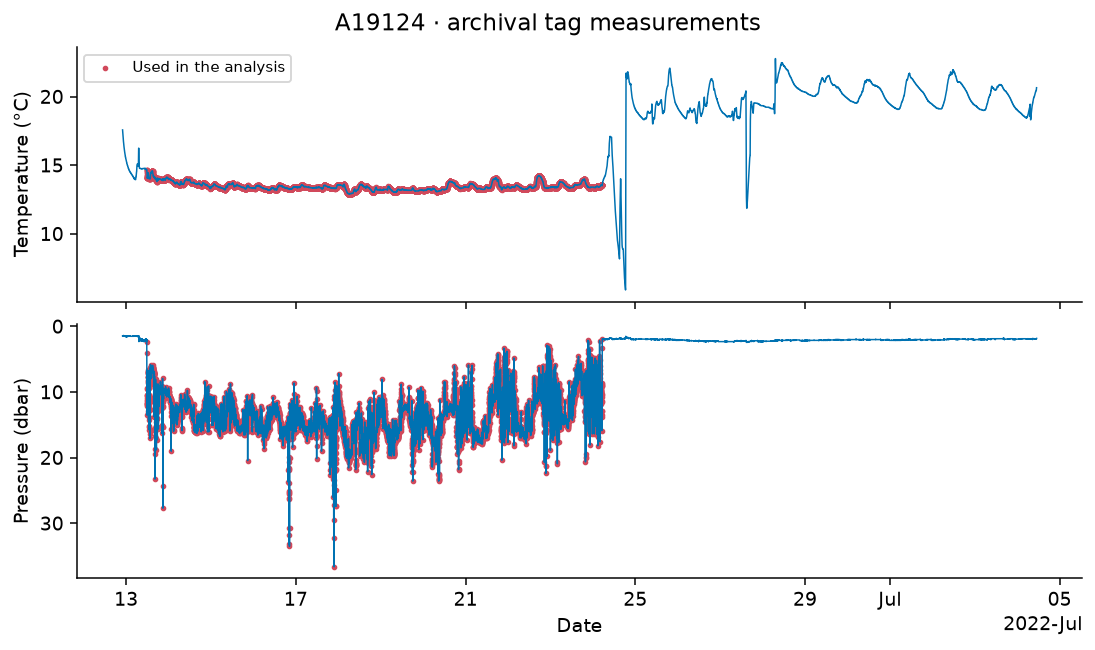

In [10]:
from pangeo_fish.helpers import plot_tag

plot = plot_tag(
    tag=tag,
    tag_log=tag_log,
    # 必要ならプロットをそのまま保存できます
    save_html=True,
    storage_options=storage_options,
    target_root=target_root,
)
plot

赤い点は、タグが生きた魚に付いていたとみなす期間の観測で、解析に使われます。この期間が放流と再捕（または死亡）の情報と合っているかを確認し、記録に欠けている部分がないかも見てください。

### Copernicus Marine にサインインする

次のセルを実行してください。求められたら、Copernicus Marine のユーザー名とパスワードを入力します。ログイン情報は保存され、次回以降のセッションでも使われます。すでに保存されている場合は、もう一度聞かれることはありません。

サインインできないときは、講師に声をかけるか、[Copernicus Marine の認証情報ガイド](https://help.marine.copernicus.eu/en/articles/8185007-copernicus-marine-toolbox-credentials-configuration)を参照してください。

In [11]:
from pathlib import Path

import copernicusmarine

credentials_file = Path.home() / ".copernicusmarine" / ".copernicusmarine-credentials"

if credentials_file.is_file():
    print("Using saved Copernicus Marine credentials.")
else:
    copernicusmarine.login()  # 必要なときにユーザー名とパスワードを尋ねます。

## 2. タグと海洋モデルの水温を比べる

### 解析する海域の海水温を読み込む

ここでは [IBI 再解析](https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002/services)を使います。この海域をカバーする領域海洋モデルで、日ごとのデータ、解像度は約 3 km です。次のセルで、選んだ海域とタグの装着期間のデータを読み込みます。

[GLORYS12](https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030/services) は全球モデルの選択肢で、日ごとのデータ、解像度は約 9 km です。モデルを切り替えるには、上の設定セルで、いま有効な `copernicus_model_name` の行の先頭に `#` を付け、もう一方の行の先頭の `#` を外します。最初は IBI で実行してください。

In [12]:
from pangeo_fish.helpers import load_model, compute_diff

reference_model = load_model(
    uri=ref_url,
    tag_log=tag_log,
    time_slice=time_slice,
    bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
    chunk_time=chunk_time,
    remote_options={},
    copernicus_model_name=copernicus_model_name,
)

### 候補となる場所で水温を比べる

候補となる場所ごとに、タグの水温と、観測された深度でのモデルの水温を比べます。観測はモデルの時間間隔ごとにまとめられます。差が 0 に近いほど水温がよく一致していることを示しますが、似た水温の場所が複数あることもあります。

くわしい説明は[水温・深度履歴から位置の適合度を作る](science/03_temperature.md)を見てください。

In [13]:
%%time
diff = compute_diff(
    reference_model=reference_model,
    tag_log=tag_log,
    relative_depth_threshold=relative_depth_threshold,
    chunk_time=chunk_time,
    # 干潮時に水深が 0 以下になって海面の上に出るセル（1 時間ごとの North-West Shelf
    # モデルだけで生じます）は、デフォルトで除外されます。ほかの選択肢：
    # min_water_depth="auto",  # デフォルト：そのようなセルがあれば除外する
    # min_water_depth=0.5,  # 水深が 0.5 m 未満のセルも除外する
    # min_water_depth=None,  # そのようなセルも残す
)[0]
diff = diff.compute()
diff

CPU times: user 5.2 s, sys: 1.88 s, total: 7.08 s
Wall time: 2min 39s


<xarray.Dataset> Size: 7MB
Dimensions:     (lat: 198, lon: 252, time: 11)
Coordinates:
  * lat         (lat) float32 792B 46.03 46.05 46.08 46.11 ... 51.44 51.47 51.5
  * lon         (lon) float32 1kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
    latitude    (lat, lon) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (lat, lon) float32 200kB -6.999 -6.971 ... -0.05448 -0.0267
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Data variables:
    diff        (time, lat, lon) float64 4MB -2.998 -3.028 -3.052 ... nan nan
    H0          (lat, lon) float32 200kB 4.801e+03 4.792e+03 ... nan nan
    XE          (time, lat, lon) float32 2MB -0.2991 -0.2984 -0.2978 ... nan nan
    ocean_mask  (lat, lon) bool 50kB True True True True ... False False False
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...

### データがそろっているかを時間ごとに確認する

次のプロットは、時刻ごとに、水温のデータがある候補セルの数を示します。欠損値（Python では `NaN` と表されます）のセルは数えません。HMM を実行する前に、この確認が大切です。

急に減っているところや、途切れているところがないかを見てください。数が多少変動するのは問題ありませんが、急に減っている場合はデータの欠損や処理の問題かもしれません。**数が 0 になっている時刻は、その時刻に使える空間データがまったくないことを意味します。先に進む前に、講師と一緒に原因を調べてください。**

CPU times: user 17.5 ms, sys: 1.88 ms, total: 19.4 ms
Wall time: 20 ms


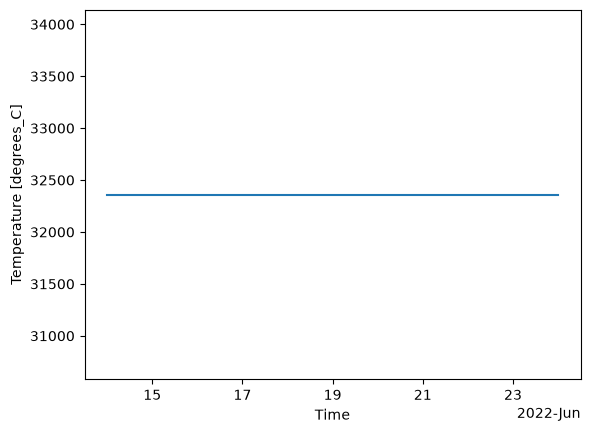

In [14]:
%%time
diff["diff"].count(["lat", "lon"]).rename("Valid grid cells").plot()

In [15]:
%%time
diff.to_zarr(
    f"{target_root}/diff.zarr", mode="w", storage_options=storage_options, zarr_format=2
)

CPU times: user 32.6 ms, sys: 56.3 ms, total: 88.9 ms
Wall time: 62.3 ms


## 3. 候補となる場所を等面積の格子で表す

水温の比較結果を、**HEALPix** と呼ばれる格子に移します。HEALPix は等面積の離散全球格子システム（DGGS）で、どのセルも地球表面上で同じ面積を持ちます。階層構造になっているため、細かい格子と粗い格子を選べます。このワークショップでは refinement level 10 を使い、セルの大きさは約 **6.4 km** です。

このセルの大きさは、推定した魚の位置の精度ではありません。位置の不確かさは、観測、海洋モデル、移動の仮定にも左右されます。また、等面積だからといって、セルの形がすべて同じになるわけでも、空間のゆがみがすべてなくなるわけでもありません。詳しくは [HEALPix のドキュメント](https://healpix.sourceforge.io/)を参照してください。

格子の設定についてのくわしい説明は[楕円体 HEALPix：位置・面積・解像度を区別する](science/09_ellipsoidal_healpix.md)を見てください。

In [16]:
from pangeo_fish.helpers import (
    open_diff_dataset,
    regrid_dataset_hpresample,
)

In [17]:
# 前のステップのデータセットを開きます（ノートブックをここから再開するときだけ必要です）
diff = open_diff_dataset(target_root=target_root, storage_options=storage_options)
diff

<xarray.Dataset> Size: 7MB
Dimensions:     (time: 11, yi: 198, xi: 252)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    latitude    (yi, xi) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (yi, xi) float32 200kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
Dimensions without coordinates: yi, xi
Data variables:
    diff        (time, yi, xi) float64 4MB dask.array<chunksize=(6, 99, 126), meta=np.ndarray>
    H0          (yi, xi) float32 200kB dask.array<chunksize=(198, 252), meta=np.ndarray>
    ocean_mask  (yi, xi) bool 50kB dask.array<chunksize=(198, 252), meta=np.ndarray>
    XE          (time, yi, xi) float32 2MB dask.array<chunksize=(6, 99, 126), meta=np.ndarray>
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...

In [18]:
reshaped, resampling_info = regrid_dataset_hpresample(
    ds=diff,
    refinement_level=refinement_level,
    ellipsoid=ellipsoid,
    dims=dims,
    mask_threshold=mask_threshold,
)
reshaped

[KNeighborsResampler] dropping 1,302 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).
[CloughTocherResampler] N=32359 samples, 64307 Delaunay triangles, K=6257 output cells retained (inside convex hull).
ocean cells not covered by Clough-Tocher : 297


iocean cells  not covered by CT nor by rewrap : 75
diff ('time', 'yi', 'xi')
H0 ('yi', 'xi')
XE ('time', 'yi', 'xi')


<xarray.Dataset> Size: 2MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    ocean_mask  (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0 1.0
    diff        (time, cells) float64 717kB nan nan nan ... -2.4 -2.094 -2.558
    H0          (cells) float64 65kB nan nan nan nan ... 82.42 82.12 82.86 80.65
    XE          (time, cells) float64 717kB nan nan nan ... -0.3025 -0.308
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    grid_type:                 healpix
    level:                     10
    nside:                     1024

In [19]:
resampling_info["bbox"] = bbox
import json

# 再格子化のメタデータと地理的な範囲を、結果と一緒に保存します。
with open(f"{target_root}/resampling_info.json", "w") as f:
    json.dump(resampling_info, f)

with open(f"{target_root}/resampling_info.json") as f:
    resampling_info = json.load(f)
resampling_info

{'resolution_2D': [252, 198],
 'refinement_level': 10,
 'ellipsoid': 'WGS84',
 'bbox': {'latitude': [46, 51.5], 'longitude': [-7, 0]}}

格子を変えたので、データがそろっているかをもう一度確認します。セルの大きさや範囲が変わったため、セルの数は前と異なることがあります。急に減っているところがないかを見て、数が 0 の時刻があれば、先に進む前に原因を調べてください。

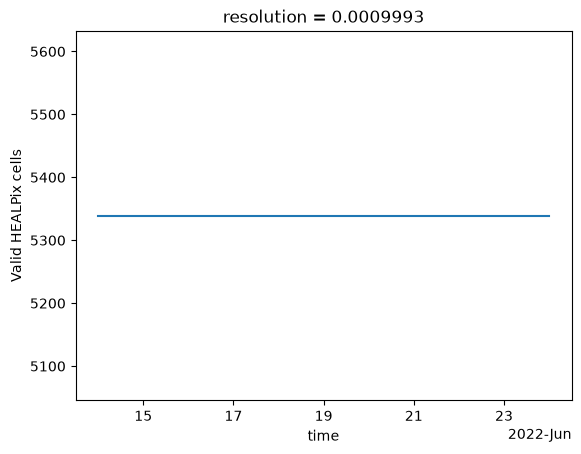

In [20]:
reshaped["diff"].count(dims).rename("Valid HEALPix cells").plot()

In [21]:
# 結果を保存します
reshaped.chunk(default_chunk_dims).to_zarr(
    f"{target_root}/diff-regridded.zarr",
    mode="w",
    consolidated=True,
    compute=True,
    storage_options=storage_options,
    zarr_format=2,
)

次の地図は、水温の差（`diff`）とモデルの海底の深さ（`H0`）を示しています。水温の差の地図では、0 に近い値を探してください。よく一致する場所は 1 か所に集まっていますか、それとも何か所かに分かれていますか？ このパターンが時間とともにどう変わるかも確認してください。

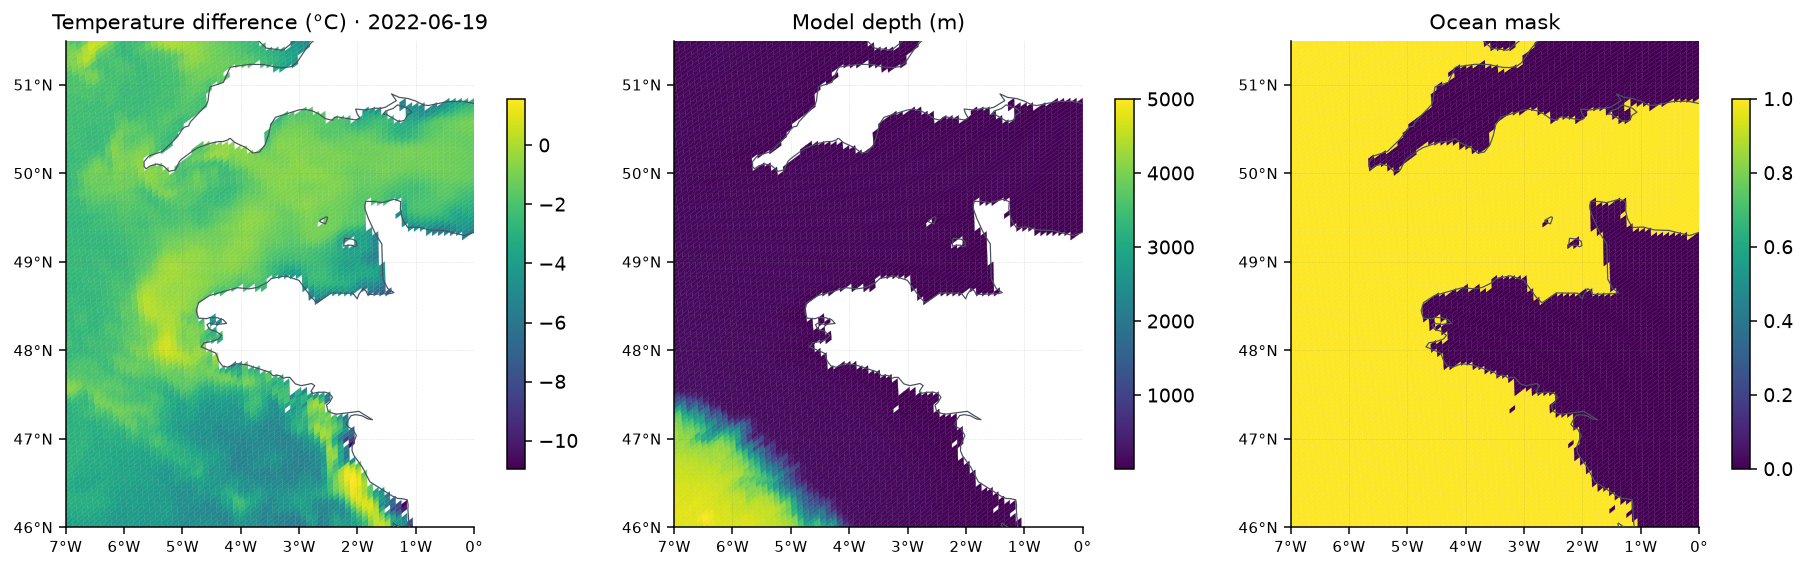

In [22]:
reshaped.healpix.plot(var=["diff", "H0", "ocean_mask"], alpha=0.5)

## 4. 水温と合う場所を見つける

モデルの水温がタグの観測と一致する場所ほど、大きな重みを与えます。この重みを**観測確率（emission probability）** と呼びます（統計学では尤度（likelihood）にあたります）。観測が、それぞれの候補の場所とどのくらい整合するかを表します。

水温の差 0 を中心とするガウス分布（正規分布）の曲線を使います。設定 `differences_std` はその幅を決めます。値を大きくすると、より大きな水温の差まで許容します。放流と再捕（または死亡）の場所も、位置を絞り込む追加の手がかりになります。

`emission_pdf["pdf"]` に保存される水温の重みは、この段階ではまだ場所全体で合計しても 1 になりません。「8. 確率分布を統合する」で手がかりを統合し、正規化します。

In [23]:
from pangeo_fish.helpers import compute_emission_pdf

In [24]:
# 前のステップのデータセットを開きます（ノートブックをここから再開するときだけ必要です）
differences = xr.open_dataset(
    f"{target_root}/diff-regridded.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

# ……そして観測確率の行列を計算します
emission_pdf = compute_emission_pdf(
    diff_ds=differences,
    events_ds=tag["tagging_events"].ds,
    differences_std=differences_std,
    initial_std=initial_std,
    recapture_std=recapture_std,
    dims=dims,
    chunk_time=chunk_time,
)[0]
emission_pdf

<xarray.Dataset> Size: 1MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
  * cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/15)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    grid_type:                 healpix
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001

水温の重み（`pdf`）を、放流（`initial`）と最終位置（`final`、ある場合）の地図と比べてください。水温の観測から、狭い範囲に絞り込めていますか？ それとも、可能性のある海域がいくつも残っていますか？

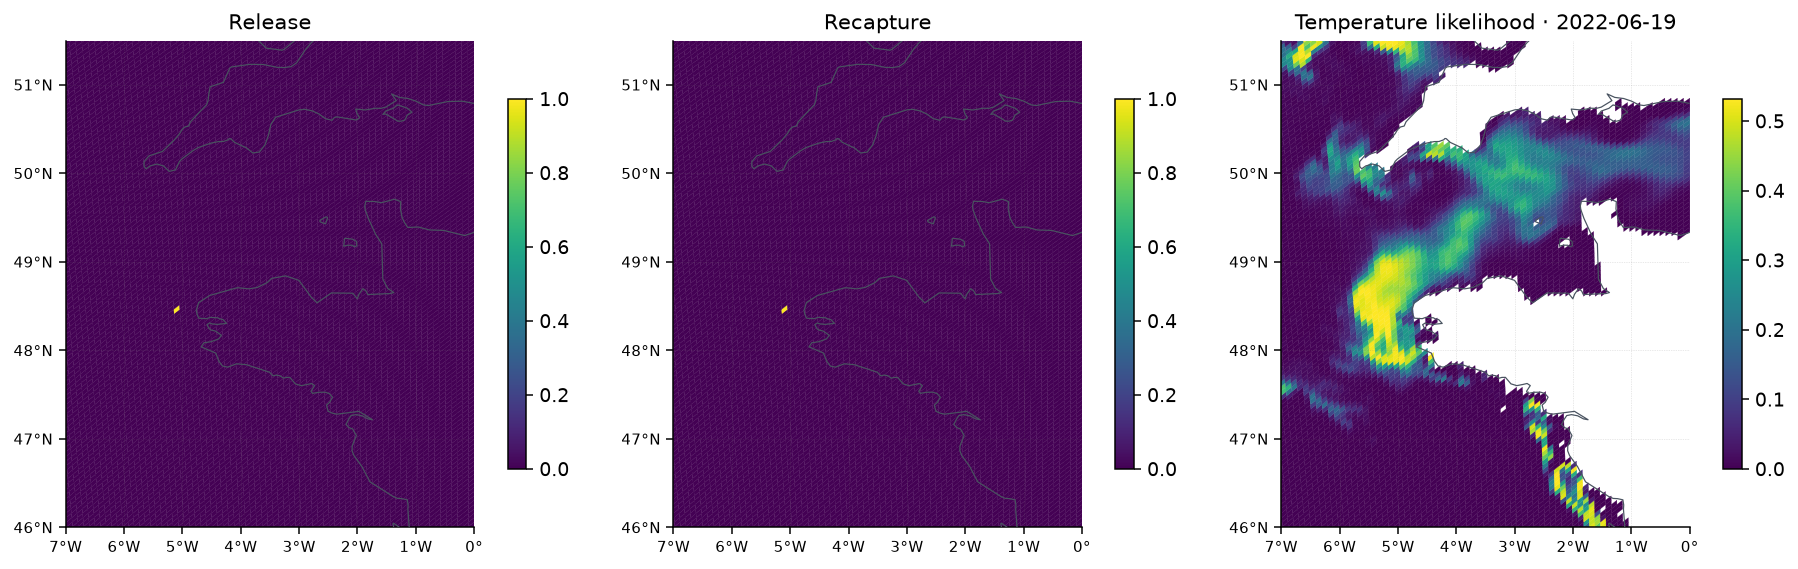

In [25]:
emission_pdf.healpix.plot(["initial", "final", "pdf"])

各時刻で、全セルの水温による尤度（likelihood）を合計した値を確認します。この段階では 1 でなくて構いません。

- `NaN`：その時刻にはデータがありません。
- `0`：データはありますが、タグの水温と一致する場所がひとつもありません。

どちらかが現れたら、先に進む前に原因を調べてください。

Time steps without data (NaN): 0
Time steps with zero total weight: 0


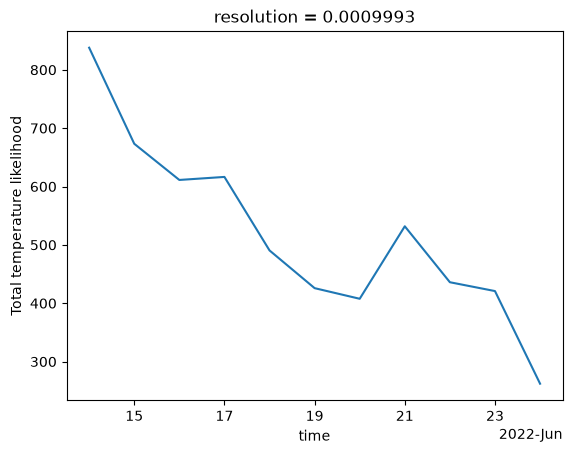

In [26]:
emission_pdf = emission_pdf.chunk(default_chunk_dims).persist()
total = (
    emission_pdf["pdf"].sum(dims, min_count=1).rename("Total temperature likelihood")
)
print("Time steps without data (NaN):", int(total.isnull().sum()))
print("Time steps with zero total weight:", int((total == 0).sum()))
total.plot()

In [27]:
# データセットを保存します
emission_pdf.to_zarr(
    f"{target_root}/emission_diff.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [28]:
emission_pdf.attrs["sources"] = emission_pdf.attrs.get("sources", []) + [
    "temperature"
]  # これまでに加えた手がかりの種類を記録します。
emission_pdf.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

## 5. 音響テレメトリーの受信記録を加える

受信記録は、その時刻に魚が受信機の想定受信範囲の中にいたことを教えてくれます。この情報を使って、水温による手がかりを補いながら、魚がいた可能性のある場所を絞り込みます。

このステップには、タグのデータに音響テレメトリーの受信記録と受信機の位置が含まれている必要があります。設定 `receiver_buffer` で想定する受信範囲を決めます。この手がかりは、「8. 確率分布を統合する」で水温の手がかりと統合します。

くわしい説明は[音響観測による位置制約：検出と非検出](science/05_acoustic.md)を見てください。

In [29]:
from pangeo_fish.helpers import compute_acoustic_pdf

In [30]:
# 受信記録の時刻の単位を、ほかのデータと同じナノ秒にそろえます。
# pandas 3 では受信記録の時刻がマイクロ秒で読み込まれ、単位が違うと
# 受信記録を 1 件も数えられません（pangeo-fish の不具合を避けるための処理です）。
acoustic = tag["acoustic"].to_dataset()
tag["acoustic"] = acoustic.assign_coords(time=acoustic["time"].astype("datetime64[ns]"))

In [31]:
# 前のステップの観測確率を読み込み、音響テレメトリーの受信記録にもとづく観測確率を計算します
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
acoustic_pdf = compute_acoustic_pdf(
    emission_ds=emission_diff,
    tag=tag,
    receiver_buffer=receiver_buffer,
    chunk_time=chunk_time,
    dims=dims,
)[0]
acoustic_pdf = acoustic_pdf.persist()
acoustic_pdf

<xarray.Dataset> Size: 912kB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
  * cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    receiver_buffer:           2000 meter

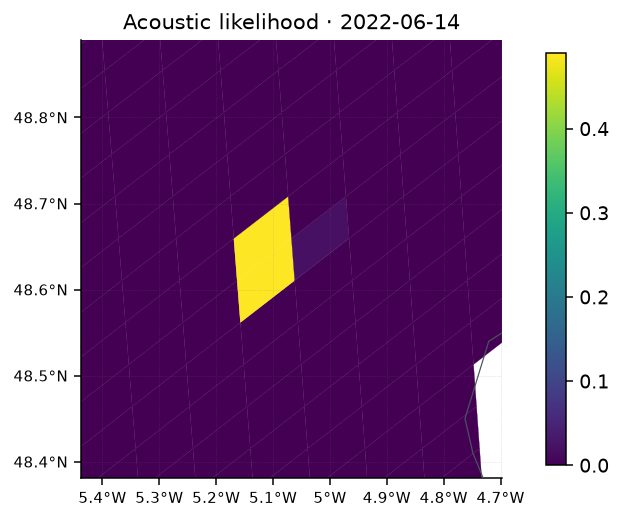

In [32]:
acoustic_pdf.healpix.plot("acoustic")

受信があった時刻と、可能性のあるセルの数の目安を並べた図です。曲線は目安です。受信の前後で変わるかを見てください。

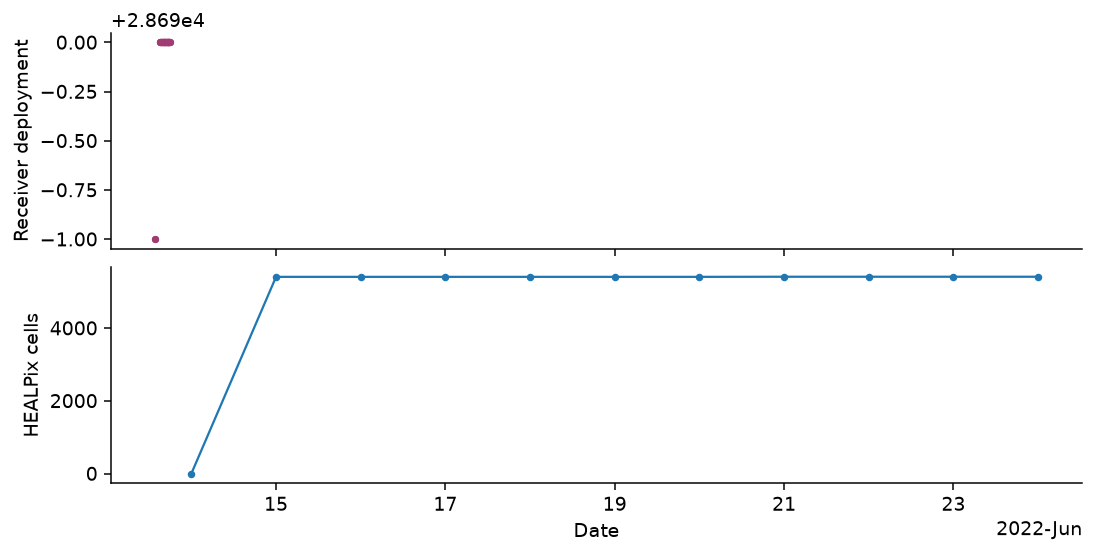

In [33]:
tag["acoustic"]["deployment_id"].hvplot.scatter(c="red", marker="x") * (
    acoustic_pdf["acoustic"] != 0
).sum(dim=dims).hvplot()

受信があった時刻には、想定した受信範囲のもとで、可能性のある場所が受信機の周りに一気に絞り込まれることがあります。受信記録は、位置を強く制約する手がかりです。曲線の高さではなく、受信の時刻に合わせた曲線の変化を見てください。

次のセルでは、必要に応じて音響テレメトリーの結果を別に保存します。このあとの解析では、すでに計算した結果をそのまま使えます。

In [34]:
acoustic_pdf.to_zarr(
    f"{target_root}/acoustic.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

### 手がかりをまとめる

In [35]:
# いま保存されている手がかりを開きます。
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 1MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature']

In [36]:
if "acoustic" in current_total.data_vars:
    pass
else:
    current_total = current_total.load()
    current_total.attrs["sources"] = current_total.attrs.get("sources", []) + [
        "acoustic"
    ]

    merged_pdf = current_total.merge(
        acoustic_pdf.drop_indexes(["cell_ids"]), compat="override"
    )

    merged_pdf.to_zarr(
        f"{target_root}/total_pdf.zarr",
        mode="w",
        consolidated=True,
        storage_options=storage_options,
        zarr_format=2,
    )
merged_pdf

<xarray.Dataset> Size: 2MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    initial     (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    mask        (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 717kB nan nan nan ... 0.0108 0.001587
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic']

## 6. 海底地形の情報を加える

このステップでは、GEBCO や EMODnet などの海底地形データを使って、もうひとつの観測確率の分布を計算します。

この確率を加えることで、前のステップで作った観測確率に海底地形の情報が取り込まれます。

セルごとの尤度（likelihood）は、その日に魚が潜った最も深い深度（海面から測った深度）よりも、そのセルの海底が深い確率です。1 つのセルの中には浅い部分と深い部分があるので、セルの海底の深さは、セルに含まれる GEBCO の水域の点の分布として扱います（陸の点は除きます）。そのため、浅い部分と深い部分の両方があるセルにも、ある程度の確率が残ります。深度の記録がない日は海底地形の手がかりがないので、海のすべてのセルの尤度（likelihood）が同じ値（1）になります。つまり、その日はどの場所も区別しません。

**注意：** このステップでは、HEALPix への変換で書き出した `diff-regridded.zarr`（海面高度 `XE` を含みます）を読み込みます。

くわしい説明は[海底地形による制約：潜れた深さとセル内の地形](science/06_bathymetry.md)を見てください。

### データの読み込み

海洋の参照モデルと、「2. タグと海洋モデルの水温を比べる」で計算した水温の差（diff）を読み込みます。海底地形のデータも読み込みます。

In [37]:
if "reference_model" in locals():
    pass
else:
    from pangeo_fish.helpers import load_model

    reference_model = load_model(
        uri=ref_url,
        tag_log=tag_log,
        time_slice=time_slice,
        bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
        chunk_time=chunk_time,
        remote_options={},
        copernicus_model_name=copernicus_model_name,
    )
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

In [38]:
import fsspec
import numpy as np
from pangeo_fish.cf import bounds_to_bins
from pangeo_fish.tags import adapt_model_time, reshape_by_bins, to_time_slice
from pangeo_fish.bathy import batch_compute_pdf_bathy
from pangeo_fish.bathy import (
    compute_healpix_histogram_region_bin_size,
)

# GEBCO 2024 の海底地形（標高、単位は m。海面より下は負の値）
bathy_url = "https://data-taos.ifremer.fr/demo/database/gebco_2024_new.zarr/"

nside = (
    2**refinement_level
)  # refinement level に相当するパラメータ。一部の関数で使います
full_bathy = xr.open_dataset(
    bathy_url,
    engine="zarr",
    chunks={},
    storage_options=None,
    zarr_format=2,
).rename({"lat": "latitude", "lon": "longitude"})
full_bathy

<xarray.Dataset> Size: 7GB
Dimensions:    (latitude: 43200, longitude: 86400)
Coordinates:
  * latitude   (latitude) float64 346kB -90.0 -89.99 -89.99 ... 89.99 89.99 90.0
  * longitude  (longitude) float64 691kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    crs        |S1 1B ...
    elevation  (latitude, longitude) int16 7GB dask.array<chunksize=(1000, 1000), meta=np.ndarray>

In [39]:
subset_bathy = full_bathy.sel(
    {dim: slice(bounds[0] - 0.1, bounds[1] + 0.1) for dim, bounds in bbox.items()}
)

In [40]:
ds_histo = compute_healpix_histogram_region_bin_size(
    subset_bathy,
    nside=nside,
    # 深度は max_depth_m まで区別します。それより深い場所にいた魚には、
    # セルの海底のうち max_depth_m より深い部分の割合を与えます。
    max_depth_m=1000,
    # ビンの幅（m）。尤度（likelihood）はビンの中で線形に補間するため、
    # ビンを広げると海底の深さが最大で 1 ビン分ぼけます。ビンを狭くするとメモリを多く使います。
    # 最後の区間は max_depth_m で終わるので、幅が短くなることがあります。
    depth_bin_size=2,
    ellipsoid=ellipsoid,
)

確率分布を計算します。

In [41]:
from pangeo_fish.bathy import batch_compute_pdf_bathy

reshaped_tag = reshape_by_bins(  # 確率分布を計算するためにタグのデータを整形します
    tag_log,
    dim="time",
    bins=(
        reference_model.cf.add_bounds(["time"], output_dim="bounds")
        .pipe(bounds_to_bins, bounds_dim="bounds")
        .get("time_bins")
    ),
    other_dim="obs",
).chunk({"time": chunk_time})

pdf_da_func = batch_compute_pdf_bathy(
    ds_histo,
    reshaped_tag,
    target_root,
    batch_size=10000,
)

sum_over_cells = pdf_da_func.sum(dim="cells", skipna=True)
bathy_pdf = pdf_da_func / sum_over_cells  # 正規化
bathy_pdf

Batch cells 0–8145


<xarray.Dataset> Size: 782kB
Dimensions:    (time: 11, cells: 8145)
Coordinates:
  * time       (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * cell_ids   (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
Dimensions without coordinates: cells
Data variables:
    pdf_bathy  (time, cells) float64 717kB nan nan nan ... 0.0002034 0.0002034

次のセルでは、必要に応じて海底地形の結果を別に保存します。このあとの解析では、すでに計算した結果をそのまま使えます。

In [42]:
bathy_pdf.compute().to_zarr(
    f"{target_root}/bathy_pdf_{tag_name}.zarr",
    compute=True,
    mode="w",
    consolidated=True,
    zarr_format=2,
    storage_options=storage_options,
)

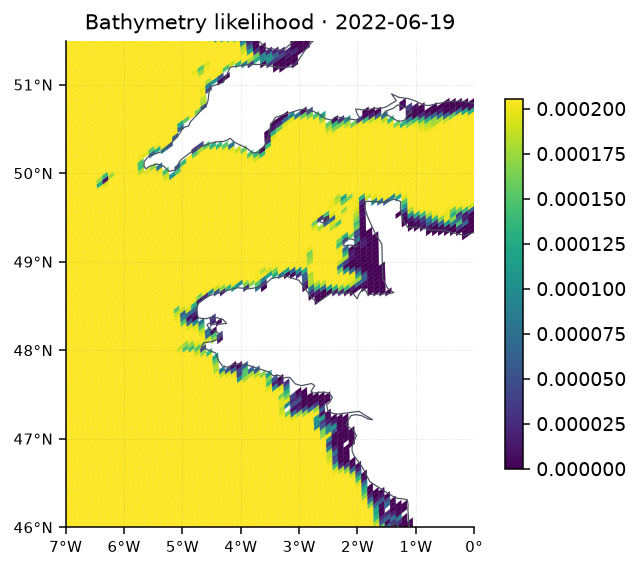

In [43]:
# 確率分布を見たいとき
bathy_pdf.healpix.plot("pdf_bathy", refinement_level=refinement_level)

### 手がかりをまとめる

In [44]:
# ほかの確率分布が入ったデータセットを開きます
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

In [45]:
# 保存してあった海底地形の確率分布を、今回の計算結果に置き換えます。
current_total = current_total.drop_vars("pdf_bathy", errors="ignore").load()
current_total.attrs["sources"] = list(
    dict.fromkeys([*current_total.attrs.get("sources", []), "bathymetry"])
)
# 保存してあるデータは、すでに潮汐の格子と日付に絞り込まれていることがあります。
aligned_bathy = bathy_pdf.sel(
    cell_ids=current_total.cell_ids.values, time=current_total.time.values
)
merged_pdf = current_total.merge(
    aligned_bathy.drop_indexes(["cell_ids"]), compat="override"
)

merged_pdf.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
merged_pdf

<xarray.Dataset> Size: 3MB
Dimensions:     (time: 11, cells: 8145)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB nan nan nan ... 0.0001228 0.0001228
    final       (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    initial     (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    mask        (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 717kB nan nan nan ... 0.0108 0.001587
    pdf_bathy   (time, cells) float64 717kB nan nan nan ... 0.0002034 0.0002034
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic', 'bathymetry']

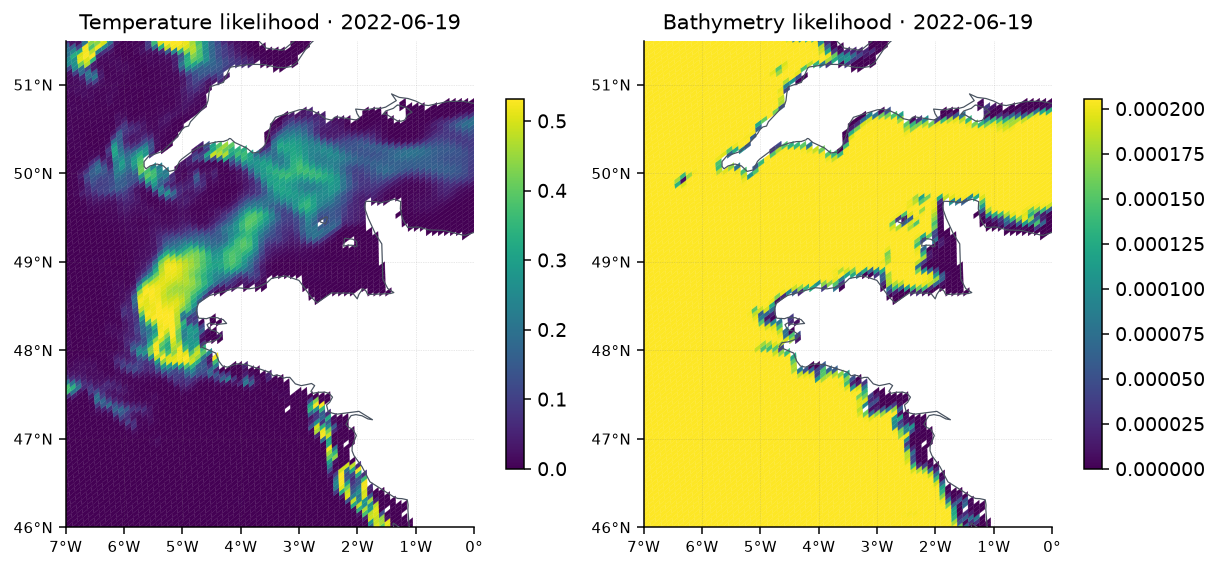

In [46]:
liste = multiplot_healpix(
    [(merged_pdf, ["pdf", "pdf_bathy"])],
)

multi_map_with_synced_sliders(liste)

## 7. 潮汐による手がかりを加える

潮汐は、タグが記録した深度の上下（潮の満ち引き）を、潮汐モデルが予測する水位の変化と比べて、場所を絞る手がかりです。最初は `"healpix"`（デフォルト）のまま使ってください。

ノートブックの冒頭にある **解析の設定** で、**`tide_method`** を選びます。

- **`"healpix"`**（デフォルト）：1 時間ごとの深度の平均を、各セルで予測した潮汐と比べ、セルごと・日ごとに未知の平均深度を推定します。潮汐の形を使い、モデルの誤差の大きさには `tide_sigma_m` を使います。この方法は海底の深さ（水深）を使いません。水深の情報は、「6. 海底地形の情報を加える」の海底地形の尤度（likelihood）が受け持ち、「8. 確率分布を統合する」で潮汐と掛け合わせます。
- **`"pedersen"`**：[Pedersen et al. (2008)](https://doi.org/10.1139/f08-144) の方法です。記録された深度を、各セルで予測される深さ（平均水深 + 潮汐）と比べて、尤度（likelihood）を計算します。

どちらの方法も、セルごとの潮汐の調和定数と、`detect_tide` を使います。調和定数から各セルの潮位を予測する計算には、PyFES（CNES が開発した潮汐予測のライブラリ）を使います。`detect_tide` は、深度の記録から、潮汐の影響が見える時間帯を自動で選びます（魚が海底でじっとしていることを仮定しています）。そのような時間帯がない日は、潮汐は手がかりにならず、どの場所も同じ重みになります。ワークショップの環境には pyfes が入っています（自分の環境に入れる方法は pangeo-fish のドキュメントを見てください）。

どちらの方法もデフォルトでは TPXO9 を使います。FES2022b を使うには、`tide_model = "fes2022b"` を選び、`tide_model_source` にローカルの AVISO の NetCDF ファイルを指定するか、`tide_constants_store` に計算済みの Zarr を指定します。`ellipsoid` は `"WGS84"` のまま、変更しないでください。出力を比べるときは、実行ごとに別の `scratch_root` を使ってください。仮定と限界、それぞれの方法をいつ使うかについては、[潮汐の手法のドキュメント](https://github.com/pangeo-fish/pangeo-fish/blob/main/docs/tide.rst)を参照してください。

くわしい説明は[潮汐から位置を絞る：海面高度、着底区間、調和定数](science/07_tides.md)を見てください。

In [47]:
import fsspec

from pangeo_fish.tide import (
    check_tide_method,
    check_tide_sigma,
    detect_tide,
    merge_tide_with_total,
    plot_tide,
)

Tide signal extraction (25.0 h)...


Relaxed behaviour fit (25.0 h)...



Extraction done


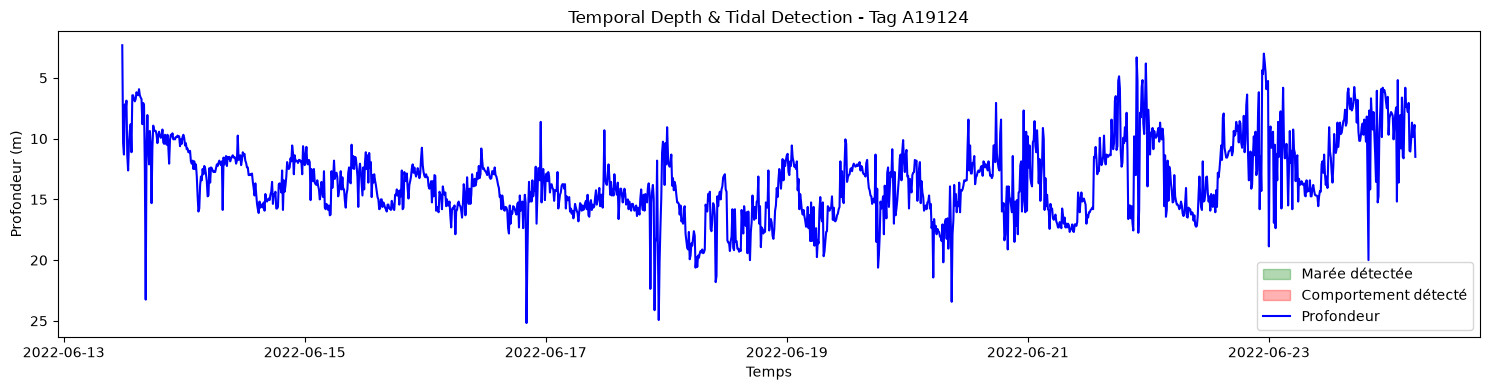

<xarray.Dataset> Size: 124kB
Dimensions:      (time: 1546)
Coordinates:
  * time         (time) datetime64[ns] 12kB 2022-06-13T11:40:00 ... 2022-06-2...
Data variables:
    depth        (time) float64 12kB 2.31 10.37 11.31 7.18 ... 9.5 8.87 11.5
    rmse_tide    (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    rsq_tide     (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    ampli_tide   (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    tide_found   (time) int64 12kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    rmse_behav   (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    rsq_behav    (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    ampli_behav  (time) float64 12kB nan nan nan nan nan ... nan nan nan nan nan
    behav_found  (time) int64 12kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
Attributes:
    tagno:         A19124
    tideFL:        25.0
    tideLV:        [0.42, 0.85, 0.6]
    behavFL:       25.0
    behavLV:       [0.42, 0.7, 0.2]
    dt:            10
    ampli_max:     5.0
    trend_order:   1
    periods_h:     [12.42]
    min_coverage:  0.8

In [48]:
tag_test = detect_tide(tag_log, tag_name)
plot_tide(tag_test)
tag_test

### 選んだ方法で日ごとの潮汐の確率分布を作る

TPXO9 では、デモ用の URL またはローカルの TMD3 ファイルを指定できます。FES2022b では、AVISO の元の NetCDF ファイルか、計算済みの WGS84 の HEALPix Zarr を選びます。

In [49]:
if not tide_constants_store:
    model_source = tide_model_source or (
        "https://data-taos.ifremer.fr/demo/database/Subset_NS_EC_forTMD30_21_2_2025.nc"
    )
    if tide_model == "fes2022b":
        model_source = str(Path(model_source).expanduser())
    tide_file = fsspec.open_local(
        f"simplecache::{model_source}"
        if model_source.startswith(("https://", "http://"))
        else model_source
    )
print(f"Tide method: {tide_method} | Tide model: {tide_model}")

Tide method: healpix | Tide model: tpxo9


In [50]:
check_tide_method(tide_method)
check_tide_sigma(tide_method, tide_sigma_m)  # この方法が tide_sigma_m を使わない場合は警告します
from pangeo_fish.tide_healpix import (
    PHASE_CONVENTION,
    cell_bathymetry,
    constants_to_healpix,
    fes2022b_constants_to_healpix,
    latlon_constants_from_tmd,
    open_harmonic_constants,
    pedersen_tide_likelihood,
    still_tag_tide_likelihood,
    write_tide_pdf_healpix,
)

if tide_constants_store:
    tide_storage_options = None
    if tide_constants_store.startswith("s3://"):
        tide_storage_options = {"config_kwargs": {"s3": {"addressing_style": "path"}}}
        if tide_s3_endpoint:
            tide_storage_options["endpoint_url"] = tide_s3_endpoint
    with open_harmonic_constants(
        tide_constants_store,
        cell_ids=merged_pdf.cell_ids,
        constituents=tide_constituents,
        storage_options=tide_storage_options,
        ellipsoid="WGS84",
        require_all_cells=True,
    ) as stored:
        if stored.attrs.get("tide_model") != tide_model:
            raise ValueError(f"Expected harmonic constants from {tide_model}")
        for name in ("tide_real", "tide_imag"):
            attrs = stored[name].attrs
            if (
                attrs.get("units") != "m"
                or attrs.get("phase_convention") != PHASE_CONVENTION
            ):
                raise ValueError(f"Unexpected units or phase convention for {name}")
        constants = stored.load()
elif tide_model == "fes2022b":
    constants = fes2022b_constants_to_healpix(
        tide_file, merged_pdf.cell_ids, constituents=tide_constituents
    )
else:
    constants = constants_to_healpix(
        latlon_constants_from_tmd(tide_file, bbox=bbox), merged_pdf.cell_ids
    )
if tide_method == "pedersen":
    # セルごとの平均水深とその分散。「6. 海底地形の情報を加える」で切り出した GEBCO から求めます
    bathy_cells = cell_bathymetry(subset_bathy.elevation, merged_pdf.cell_ids)
    likelihood = pedersen_tide_likelihood(
        tag_test.depth.to_series(),
        constants,
        bathy_cells.water_column,
        tide_found=tag_test.tide_found.to_series(),
        rmse=tag_test.rmse_tide.to_series(),
        window_hours=tag_test.attrs["tideFL"],
        bathy_variance=bathy_cells.bathy_variance,
    )
else:
    likelihood = still_tag_tide_likelihood(
        tag_test.depth.to_series(),
        constants,
        sigma=tide_sigma_m,
        valid=(tag_test.tide_found > 0).to_series(),
        min_samples=tide_min_samples,
    )
# ラベル T の日は (T - 12 h, T + 12 h] を表します。尤度（likelihood）や水温と同じ区切りです
daily_behaviour = tag_test.behav_found.resample(
    time="1D", offset="12h", closed="right"
).max()
daily_behaviour = daily_behaviour.assign_coords(
    time=daily_behaviour.time + np.timedelta64(12, "h")
)
write_tide_pdf_healpix(likelihood, target_root, behav_found=daily_behaviour)

'./test/wgs84/A19124/tide_pdf_healpix.zarr'

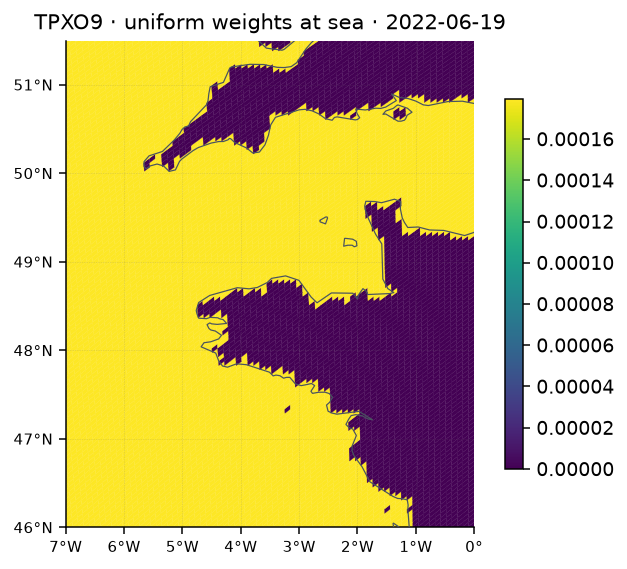

In [51]:
tide_daily = xr.open_dataset(
    f"{target_root}/tide_pdf_healpix.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
tide_daily.assign(pdf=tide_daily.pdf.clip(min=0)).healpix.plot("pdf")

> 今回の A19124 では、潮汐尤度（tide likelihood）を計算できる日がありませんでした。図の海域では重みが一様で、潮汐による位置の絞り込みはありません。

### ほかの確率分布と統合する

In [52]:
emission_with_tide, tide_mask, behav_mask = merge_tide_with_total(
    target_root, storage_options
)
# 確率分布は負になってはいけません（念のための処理です。どちらの潮汐の方法も 0 以上の値を返します）。
emission_with_tide["pdf_tide"] = emission_with_tide["pdf_tide"].clip(min=0)
emission_with_tide.attrs["tide_method"] = tide_method
emission_with_tide.attrs["tide_model"] = tide_model

In [53]:
emission_with_tide.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
emission_with_tide

<xarray.Dataset> Size: 3MB
Dimensions:     (time: 11, cells: 8145)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    pdf_bathy   (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    pdf_tide    (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
Attributes: (12/18)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic', 'pdf_tide', 'bathy...
    tide_method:               healpix
    tide_model:                tpxo9

## 8. 確率分布を統合する

それぞれの確率密度関数を掛け合わせ、最終位置の情報があればそれも加えます。そのうえで、各時刻で合計が 1 になるように、セル全体の重みの合計で割ります。これを**正規化**と呼びます。

この結果は、観測から見て、それぞれの候補の場所がどのくらい支持されるかを表します。場所を時間方向につなぐには、さらに移動モデルが必要です。

In [54]:
from pangeo_fish.helpers import normalize_pdf

In [55]:
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 3MB
Dimensions:     (time: 11, cells: 8145)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    pdf_bathy   (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
    pdf_tide    (time, cells) float64 717kB dask.array<chunksize=(3, 8145), meta=np.ndarray>
Attributes: (12/18)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic', 'pdf_tide', 'bathy...
    tide_method:               healpix
    tide_model:                tpxo9

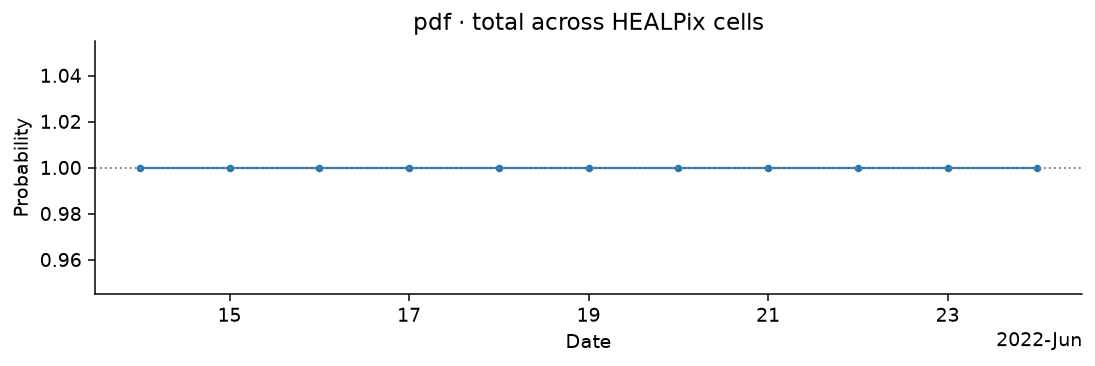

In [56]:
emission_pdf = normalize_pdf(
    ds=current_total,
    chunks=default_chunk_dims,
    dims=dims,
    exclude=("initial", "final", "mask"),
    excluded_pdf=None,  # ("pdf",)
)[0]

emission_pdf.to_zarr(
    f"{target_root}/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
combined = emission_pdf

emission_pdf["pdf"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

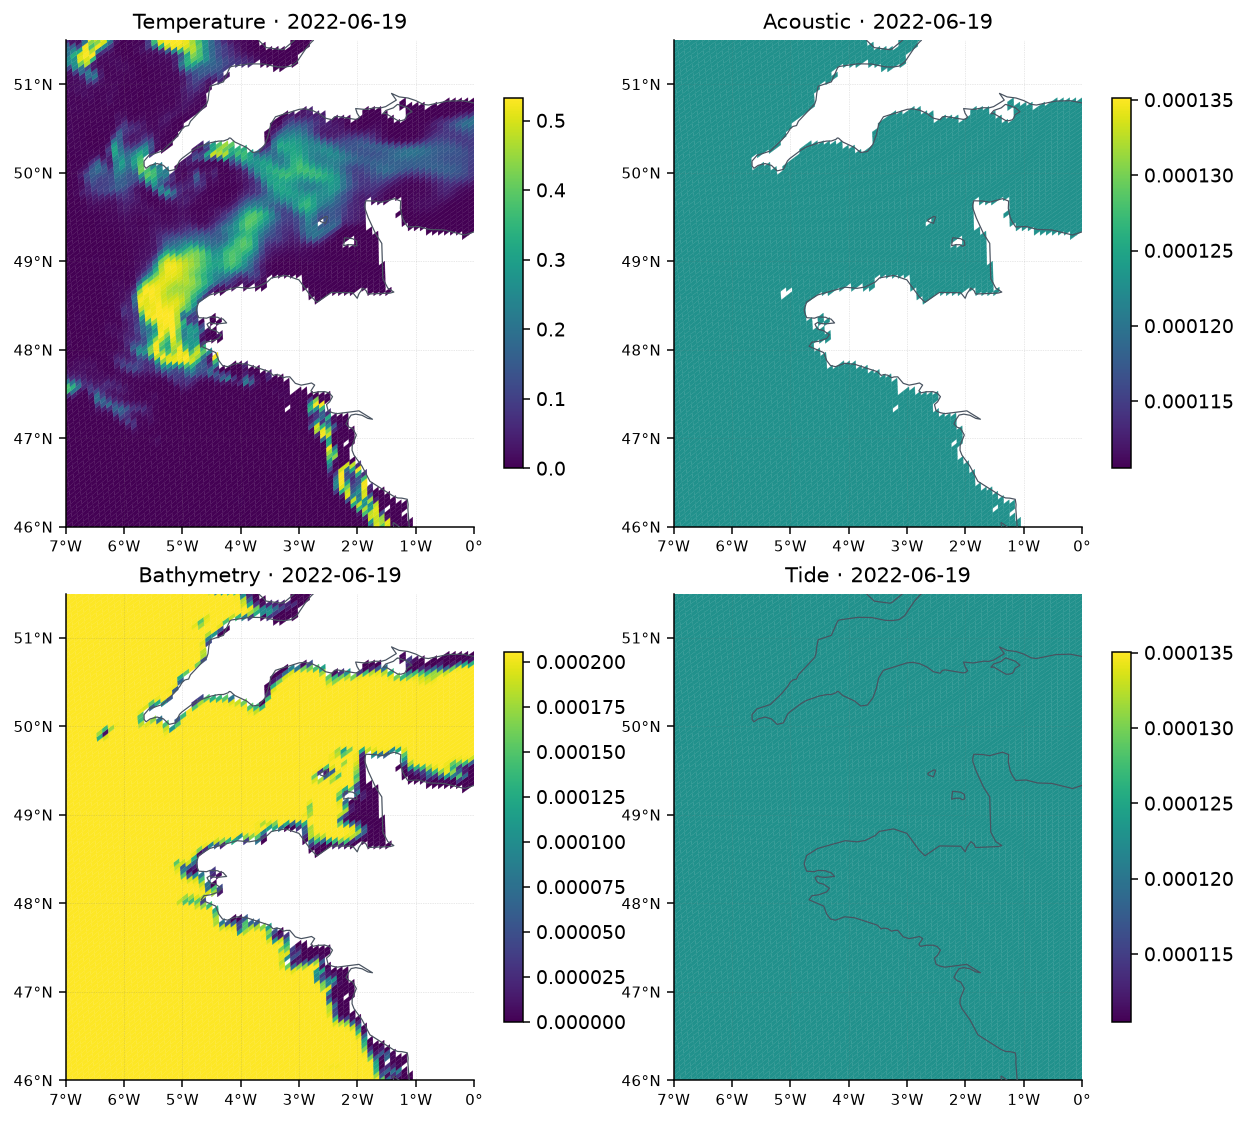

In [57]:
excluded_variables = ["final", "initial", "mask"]

names = [v for v in current_total.data_vars if v not in excluded_variables]
names
liste = multiplot_healpix(
    [(current_total, names)],
)

multi_map_with_synced_sliders(liste)

確率の合計は、どの時刻でもほぼ **1** になるはずです。データのない時刻も、1 からずれた値（合計が 0）として現れます。そのような時刻があれば、移動モデルを推定する前に原因を調べてください。

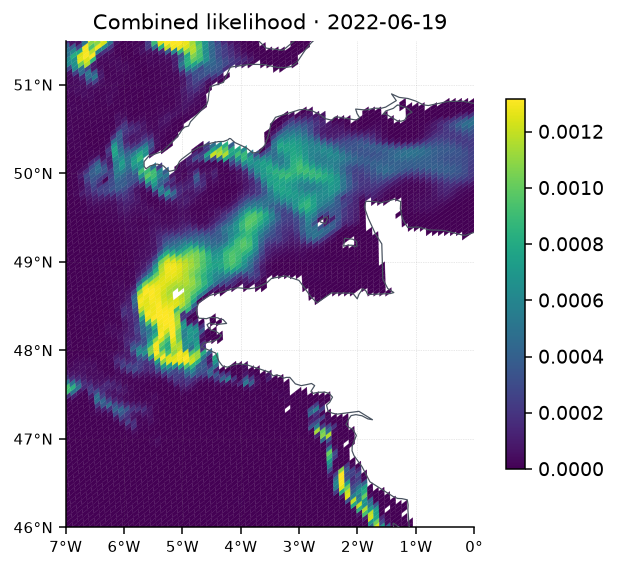

In [58]:
combined.healpix.plot("pdf")

## 9. 魚がどのくらいの範囲を移動できるかを推定する

移動モデルは、連続する時刻のあいだで、魚がいた可能性のある場所どうしをつなぎます。そのパラメータ `sigma` は、移動がどのくらい広がりうるかを決めます。値が大きいほど、より広い範囲の移動を許します。このパラメータを観測から推定します。

次のセルを実行して、移動のパラメータを推定し、保存します。探索が警告なしに終わることを確認してください。表示される `f(x)` の値は、試した `sigma` の値での当てはまりの良さを表します。探索ではいろいろな値を試すので、毎回改善しなくても問題ありません。

移動の時間間隔は、データの日付から決まります。動画の設定 `time_step` を変えても、モデルの中の魚の移動は変わりません。

<details>
<summary>補足：パラメータの探索のしくみ</summary>

探索にはブレント法（Brent's method）を使い、`1e-4` ラジアンから上限 `maximum_speed × Δt × adjustment_factor / earth_radius` までの範囲で探します。ここで Δt は観測確率の時間座標の間隔、`earth_radius` は HEALPix 格子に保存された楕円体から求めた地球の半径（長半径。`"WGS84"` の場合は約 6378 km）です。速度の設定は `sigma` の探索範囲を決めるもので、ありうる移動のひとつひとつを厳密に制限するものではありません。

推定された値が探索範囲の端に近くないかを確認してください。探索が収束しても、その解がただひとつであることや、全体での最適解であることが保証されるわけではありません。付録では、別の値と比べることができます。推定したパラメータと計算の設定は、次のステップのために JSON ファイルに保存されます。

</details>

In [59]:
from pangeo_fish.helpers import optimize_pdf

### sigma を 1 つだけ最適化する

行動を考慮せずに、畳み込みの sigma を最適化します。「[Pangeo-Fish による魚類の位置推定](pangeo-fish.ipynb)」のノートブックを参照してください。

### 複数の sigma を最適化する

この最適化では、日によって異なる sigma を使います。ここでは潮汐の情報から、潮汐の影響が見える日と見えない日に分け、それぞれに別の sigma を推定します。こうして、日ごとに魚の移動の広がりを変えられます。

> **注意：** このデモの 2 つの `sigma` の値は、機能の使い方を示すためのもので、このタグに対する信頼できる推定値ではありません。日ごとのステップが 11 個しかなく、放流地点と最終地点が 3.6 km しか離れておらず、2 つの状態が切り替わる回数も少ないため、データからはどちらの値もほとんど決まりません。また、最適化は収束する前に 20 回の評価で打ち切られるため、返された値が最小値とは限りません。推定された 2 つの値は慎重に解釈してください。

二つの sigma の意味は[HMM による位置分布と移動経路の推定](science/02_hmm.md)を見てください。

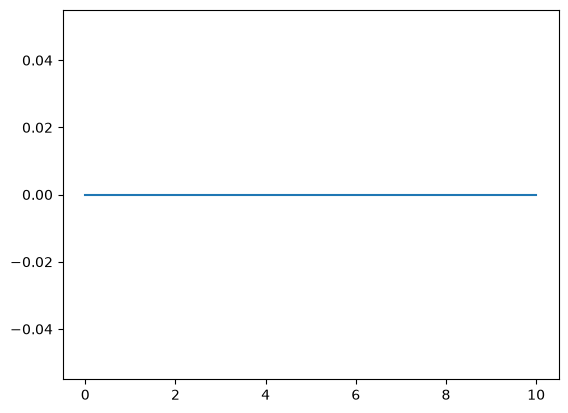

In [60]:
fit_root = f"{target_root}/two_sigma"

from pangeo_fish.helpers import (
    compute_detection_time_intervals,
    stamp_parameter_indices,
    stamp_parameter_indices_from_mask,
)
import numpy as np
import matplotlib.pyplot as plt

emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks={},
    inline_array=True,
    storage_options=storage_options,
).chunk(default_chunk_dims)

with xr.open_dataset(
    f"{target_root}/tide_pdf_healpix.zarr",
    engine="zarr",
    storage_options=storage_options,
) as tide_daily:
    # 潮汐のデータにない日は、潮汐の影響が見えた日として扱いません（0）
    behav_mask = tide_daily.behav_found.reindex(time=emission.time, fill_value=0).values

behav_mask = (behav_mask > 0).astype(np.int8)
plt.plot(behav_mask)
pdf = stamp_parameter_indices_from_mask(
    pdf=emission,
    mask=behav_mask,
    sigma_bounds_dict={0: (0, maximum_speed), 1: (0, maximum_speed / 2)},
)

In [61]:
from pangeo_fish.helpers import optimize_pdf

params, updated_emission = optimize_pdf(
    ds=pdf,
    adjustment_factor=adjustment_factor,
    truncate=truncate,
    maximum_speed=maximum_speed,
    tolerance=tolerance,
    dims=dims,
    single_behav=True,
    multivariate=True,
    # "two_sigma" という別のサブフォルダーを使います
    save_parameters=True,
    storage_options=storage_options,
    target_root=f"{fit_root}",
    conv_method="FFTConv",
)

updated_emission.attrs.pop("sigma_bounds", None)
updated_emission.to_zarr(
    f"{fit_root}/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
# 描画では、推定したモデルと同じ場所にある格子のメタデータを読み込みます。
with open(f"{fit_root}/resampling_info.json", "w") as f:
    json.dump(resampling_info, f)
params

dictionnaire des vitesses:{0: (0, <Quantity(60, 'kilometer / day')>), 1: (0, <Quantity(30.0, 'kilometer / day')>)}
dictionnaire des sigma:{0: (0.0001, 0.009407135657324388), 1: (0.0001, 0.004703567828662194)}
sigmas = [0.00475357]    score = 402.8515126640511
sigmas = [0.00365501]    score = 401.2598283305664
sigmas = [0.00585213]    score = 404.346127383609
sigmas = [0.00229712]    score = 399.16613527547173
sigmas = [0.00145789]    score = 397.79296723948033
sigmas = [0.00093922]    score = 396.8919764193708
sigmas = [0.00061867]    score = 396.2942585805878
sigmas = [0.00042056]    score = 395.6557516429262
sigmas = [0.00029811]    score = 394.95255407923656
sigmas = [0.00022244]    score = 394.8845639698754
sigmas = [0.00024191]    score = 394.8875747321613
sigmas = [0.00022633]    score = 394.8848934282662
sigmas = [0.00021495]    score = 394.88415358110365
sigmas = [0.00017104]    score = 394.88376149623315


sigmas = [0.000188]    score = 394.88377492965054
sigmas = [0.00017821]    score = 394.883763624693
sigmas = [0.00017169]    score = 394.88376159881363
sigmas = [0.00016762]    score = 394.8837611170027
sigmas = [0.00014179]    score = 394.883760746163
sigmas = [0.00015253]    score = 394.8837607551078
         Current function value: 402.851513
         Iterations: 0
         Function evaluations: 20


{'sigma': [0.00014179325109693348],
 'predictors': None,
 'predictor_factory': {'class': "<class 'pangeo_fish.hmm.prediction.FFTGaussian1DHealpix'>",
  'kwargs': {'grid_info': "HealpixInfo(level=10, ellipsoid='WGS84', indexing_scheme='nested')",
   'sigma': 'None',
   'truncate': '5',
   'kernel_size': 'None',
   'max_sigma': '0.009407135657324388',
   'max_kernel_size': 'None',
   'pixel_size_rad': 'None',
   'ellipsoid': 'WGS84',
   'max_patch_radius_deg': '10.0',
   'device': 'cpu',
   'dtype': 'torch.float64',
   'projection': 'conservative'}},
 'comment': 'pangeo-fish == 2026.11.2, healpix-convolution == 0.1.2, xarray == 2026.9.0, xhealpixify == 2025.3.3',
 'sigma_indices': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]]}

## 10. 位置を推定し、移動経路をまとめる

観測による手がかりと、推定した移動モデルを組み合わせて、各時刻にそれぞれの候補の場所に魚がいた確率を推定します。この確率分布を、次の 3 通りの方法でまとめます。

- **`viterbi_healpix`：** ビタビ（Viterbi）アルゴリズムで求めた、もっとも確からしい位置の系列全体。
- **`mode`：** 各時刻で確率がもっとも高いセル（最頻値）。
- **`mean`：** 各時刻の平均の位置。

これらの線は推定した確率分布の要約であり、実際に観測された経路ではありません。読み取るときは、確率が地図上でどのくらい広がっているかもあわせて確認してください。移動経路の連続する点のあいだの距離を km で、それに対応する速度を km/h で計算します。

<details>
<summary>補足：ほかの移動経路の求め方と計測値</summary>

ビタビ（Viterbi）アルゴリズムは、時刻ごとに別々に要約するのではなく、もっとも確からしい位置の系列全体を求めます。

`additional_track_quantities` の設定に指定できるのは `"speed"` と `"distance"` だけです。解析のあとで、返された移動経路から MovingPandas を使って、加速度（`add_acceleration`）、方向（`add_direction`）、方向の変化（`add_angular_difference`）、時間間隔（`add_timedelta`）を計算できます。これらは別の処理ステップです。[MovingPandas の trajectory API](https://movingpandas.readthedocs.io/en/main/api/trajectory.html) を参照してください。

</details>

移動経路の求め方のくわしい説明は[HMM による位置分布と移動経路の推定](science/02_hmm.md)を見てください。

In [62]:
from pangeo_fish.helpers import compute_states

states = compute_states(
    target_root=f"{fit_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    save=True,
)

`states` の確率は、各時刻で合計がほぼ **1** になるはずです。1 からずれている場合は、その時刻に欠損値や不正な値があることを意味します。

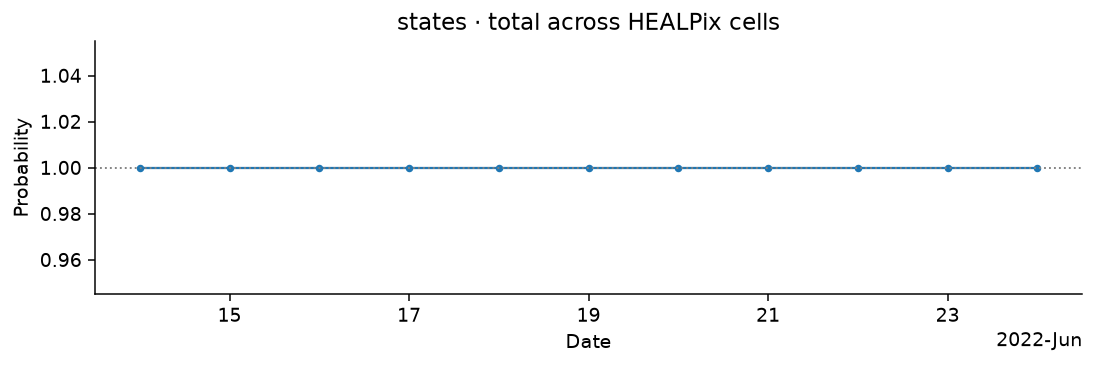

In [63]:
states["states"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

In [64]:
states = xr.open_dataset(
    f"{fit_root}/states.zarr",
    engine="zarr",
    chunks={},
    inline_array=True,
    storage_options=storage_options,
).chunk(default_chunk_dims)

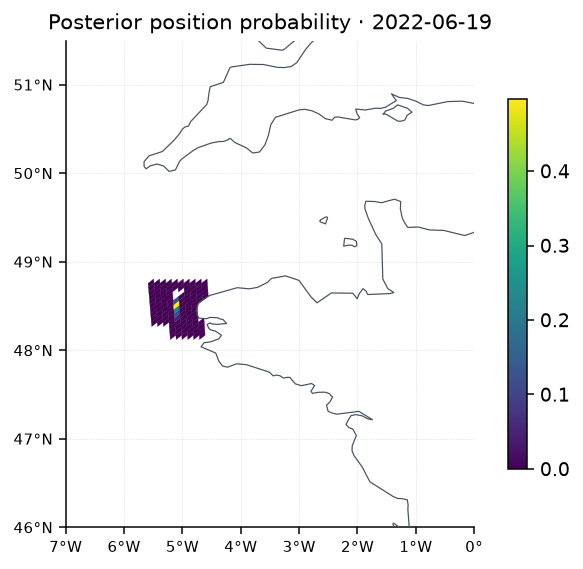

In [65]:
states.healpix.plot("states")

## 11. 地図と移動経路を見る

ビタビ（viterbi_healpix）、最頻値（mode）、平均（mean）の移動経路を比べ、確率の地図が時間とともにどう変わるかを見てみましょう。魚の位置がはっきり絞り込まれているのはどこでしょうか？ 可能性のある海域がいくつも残っているのはどこでしょうか？

**観測確率（emission）** の地図は、観測による手がかりを示します。**状態確率（state）** の地図は、時刻間の移動も考慮しています。両者のパターンを比べて、移動モデルが推定位置にどう影響しているかを確認してください。

### 11.1 移動経路を比べる

3 つの移動経路は、どこで一致し、どこで食い違っていますか？ 確率の地図を使って、その違いを読み解いてください。

比べ方と検証の考え方は[手法を比較し、推定結果を検証する](science/08_comparison_validation.md)を見てください。

In [66]:
from pangeo_fish.helpers import decode_trajectories

trajectories = decode_trajectories(
    target_root=f"{fit_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    track_modes=track_modes,
    additional_track_quantities=additional_track_quantities,
    save=True,
)

True
début
T=11,n=8145
début neighbors
nombre de sigmas demandés : 1
sigmas uniques utilisés   : 1
valeurs                   : [0.00014179]
transitions par sigma    : [10]
n=8145, T=11, level=10
sigma=0.0001418 rad | rings=2 | M(candidats)=25 | K(valides)=1 | taille table ~0 Mo
fin neighbors


fin


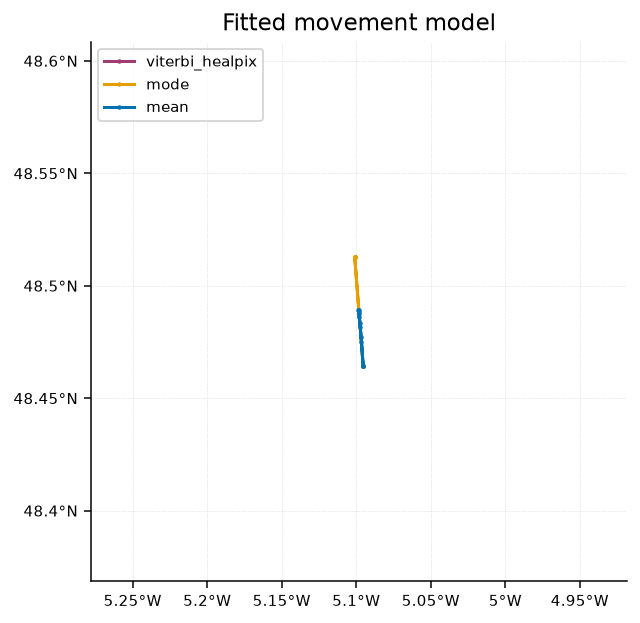

In [67]:
from pangeo_fish.helpers import plot_trajectories

plot_trajectories(
    target_root=f"{fit_root}",
    track_modes=track_modes,
    storage_options=storage_options,
    save_html=True,
)

### 11.2 確率分布の時間変化を見る

In [68]:
from pangeo_fish.helpers import open_distributions, render_distributions

In [69]:
data = open_distributions(
    target_root=f"{fit_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    chunk_time=chunk_time,
)
data

[KNeighborsResampler] dropping 76 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).


<xarray.Dataset> Size: 4MB
Dimensions:    (time: 11, latitude: 198, longitude: 252)
Coordinates:
  * time       (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * latitude   (latitude) float64 2kB 46.0 46.03 46.06 ... 51.44 51.47 51.5
  * longitude  (longitude) float64 2kB -7.0 -6.972 -6.944 ... -0.02789 0.0
Data variables:
    states     (time, latitude, longitude) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>
    emission   (time, latitude, longitude) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>

上の出力は、プロットに使えるデータの概要です。次のセルを実行すると、MP4 のアニメーションが作られ、コードのすぐ下で再生されます。

`time_step = 1` はデータのすべての時刻でフレームを作り、`3` は 3 時刻ごとにフレームを作ります。変わるのは動画のコマの間引きだけです。動画には最後の時刻のコマは含まれません。

可能性のある場所が絞り込まれる時期や広がる時期に注目し、音響テレメトリーの受信の時刻と比べてみてください。

In [70]:
import numpy as np

lon = data["longitude"].values  # (nx,)
lat = data["latitude"].values  # (ny,)
lon_2d, lat_2d = np.meshgrid(
    lon, lat
)  # (ny, nx)、2 次元の地理座標

data_2d = data.rename({"latitude": "y", "longitude": "x"})
data_2d = data_2d.assign_coords(
    longitude=(("y", "x"), lon_2d),
    latitude=(("y", "x"), lat_2d),
)
data_2d

<xarray.Dataset> Size: 5MB
Dimensions:    (time: 11, y: 198, x: 252)
Coordinates:
  * time       (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * y          (y) float64 2kB 46.0 46.03 46.06 46.08 ... 51.42 51.44 51.47 51.5
  * x          (x) float64 2kB -7.0 -6.972 -6.944 ... -0.05578 -0.02789 0.0
    longitude  (y, x) float64 399kB -7.0 -6.972 -6.944 ... -0.05578 -0.02789 0.0
    latitude   (y, x) float64 399kB 46.0 46.0 46.0 46.0 ... 51.5 51.5 51.5 51.5
Data variables:
    states     (time, y, x) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>
    emission   (time, y, x) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>

In [71]:
video_filename = render_distributions(
    data=data_2d,
    output_path=f"{fit_root}/states",
    xlim=bbox["longitude"],
    ylim=bbox["latitude"],
    time_step=time_step,
    extension="mp4",
    frames_dir="video",
    remove_frames=True,
    storage_options=storage_options,
)

  0%|          | 0/10 [00:00<?, ?it/s]

Rendering the video...:   0%|          | 0/10 [00:00<?, ?it/s]

Rendering the video...:  10%|█         | 1/10 [00:01<00:11,  1.28s/it]

Rendering the video...: 100%|██████████| 10/10 [00:01<00:00,  7.39it/s]

0it [00:00, ?it/s]

Removing .png files: : 0it [00:00, ?it/s]

Removing .png files: : 10it [00:00, 7836.89it/s]

In [72]:
from IPython.display import Video, display

display(Video(filename=video_filename, embed=True))

In [73]:
print("Your results are in:", target_root)

Your results are in: ./test/wgs84/A19124


## 研究で使うときは

このノートブックの手法を自分の研究で使った場合は、pangeo-fish の論文（Magin et al., 2026, *Journal of Open Source Software*, [doi:10.21105/joss.08332](https://doi.org/10.21105/joss.08332)）を引用してください。一緒に引用するデータやツール、pangeo-fish を使った研究の一覧は「[研究で pangeo-fish を使ったら：引用のしかた](cite.md)」のページにまとめています。

## 補足の付録：移動の仮定を比べる

ワークショップの本編はここまでです。移動の仮定がどう影響するかを調べたい方のために、次のセルでは、推定したモデルと、指定した 2 つの `sigma` の値によるモデルを比べます。確率の地図と移動経路がどう変わるかを見てください。

比較ごとに別の出力フォルダーを使います。最初の比較では、用意された設定のまま使ってください。より発展的な解析では、期間ごとに異なる移動のパラメータを使うこともできます。

In [74]:
import json
import warnings
from pathlib import Path
import fsspec
from pangeo_fish.helpers import create_parameters, hand_test_parameter
from pangeo_fish.helpers import optimize_pdf

まず、統合した観測確率の分布を別の出力フォルダーにコピーします。

In [75]:
# 確率分布を開きます
emission = xr.open_dataset(
    f"{fit_root}/combined.zarr",
    engine="zarr",
    chunks={},
    inline_array=True,
    storage_options=storage_options,
).chunk(default_chunk_dims)
# 新しいフォルダーを作ります。元データのエンコーディングではなく、現在の Dask のチャンクを使います。
for name in emission.variables:
    emission[name].encoding.pop("chunks", None)
emission.to_zarr(
    f"{fit_root}/hand_sigma0.1/combined.zarr",  # "hand_sigma0.1" は別の名前に変えてもかまいません
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [76]:
emission

<xarray.Dataset> Size: 1MB
Dimensions:          (cells: 8145, time: 11)
Coordinates:
    cell_ids         (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude         (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time             (time) datetime64[ns] 88B 2022-06-14 ... 2022-06-24
    resolution       float64 8B ...
Dimensions without coordinates: cells
Data variables:
    final            (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial          (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask             (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf              (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
    predictor_index  (time) int32 44B dask.array<chunksize=(1,), meta=np.ndarray>
Attributes: (12/21)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    sources:                   ['temperature', 'acoustic', 'pdf_tide', 'bathy...
    tide_method:               healpix
    tide_model:                tpxo9
    max_sigma:                 0.009407135657324388
    sigma:                     [0.00014179325109693348]
    predictor_factory:         {'class': "<class 'pangeo_fish.hmm.prediction....

指定した移動のパラメータを、同じフォルダーに保存します。

In [77]:
params = create_parameters(
    sigma=[0.0003],
    sigma_indices=None,
    n_steps=emission.sizes["time"],
    single_behav=True,
    class_name="FFTGaussian1DHealpix",  # 移動モデルの畳み込みクラス。
    target_root=f"{fit_root}/hand_sigma0.1",  # 上で使ったフォルダーと同じにします。
    save_parameters=True,
)
params

{'sigma': [0.0003],
 'sigma_indices': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]],
 'predictors': None,
 'predictor_factory': {'class': 'FFTGaussian1DHealpix',
  'kwargs': {'grid_info': "HealpixInfo(level=11, ellipsoid=None, indexing_scheme='nested')",
   'sigma': None,
   'truncate': None,
   'kernel_size': None,
   'projection': 'conservative'}},
 'comment': 'Custom parameters'}

別の方法として、`hand_test_parameter()` を使うと、統合した観測確率の分布と指定したパラメータを比較用のフォルダーに保存できます。既存のデータセットを `emission` として渡すか、`None` のままにして「8. 確率分布を統合する」で保存した `combined.zarr` を読み込みます。

In [78]:
params = hand_test_parameter(
    emission=None,
    sigma_tested=[0.03],
    sigma_indices=None,
    Conv_method="FFTGaussian1DHealpix",
    target_root=fit_root,
    saving_root="/hand_sigma10",
    default_chunk_dims=default_chunk_dims,
    storage_options=storage_options,
)

In [79]:
from pangeo_fish.helpers import compute_states

states_list = [
    compute_states(
        target_root=f"{fit_root}/{subfolder}",
        storage_options=storage_options,
        chunks=default_chunk_dims,
        save=True,
    )
    for subfolder in [
        "",
        "hand_sigma0.1",
        "hand_sigma10",
    ]
]

同期した地図で状態確率の分布を比べ、その下で移動経路を比べます。

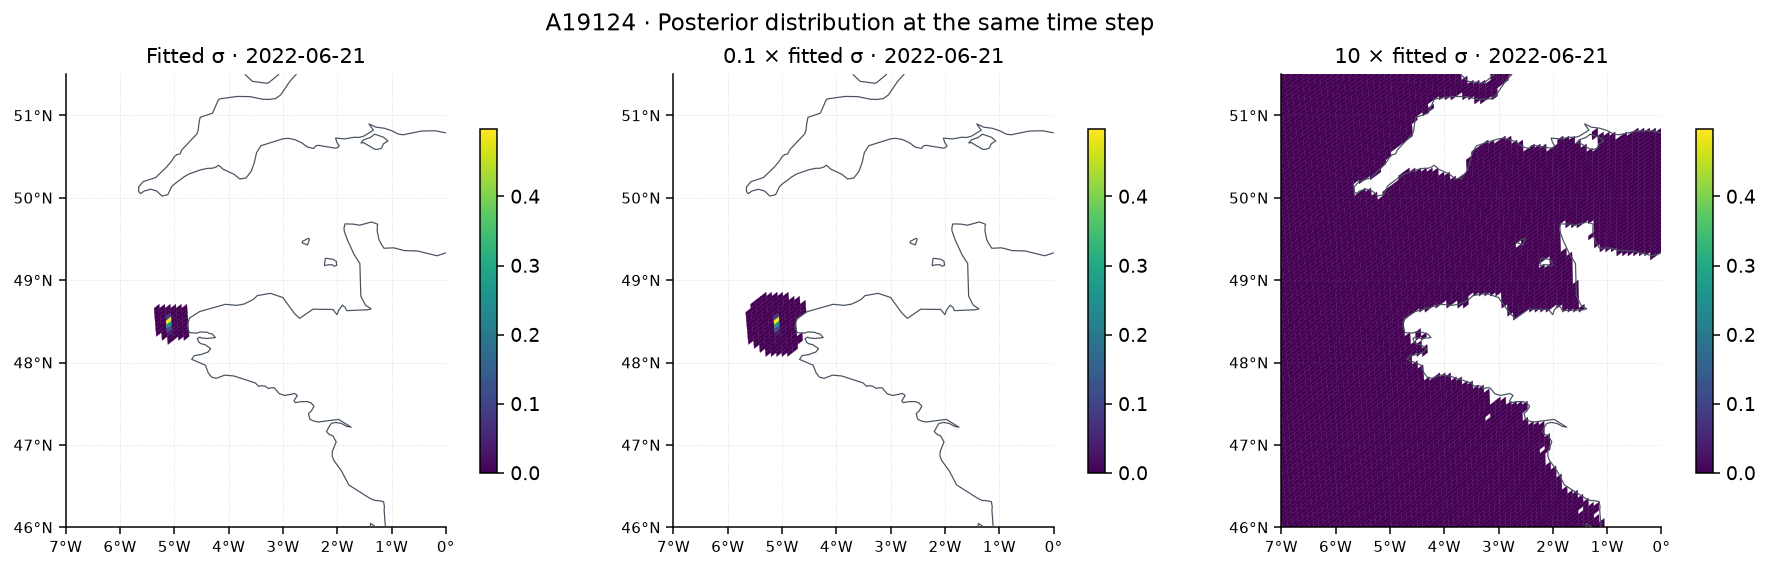

In [80]:
from pangeo_fish.helpers import multi_map_with_synced_sliders, multiplot_healpix

liste = multiplot_healpix(
    [
        (states_list[0], ["states"]),
        (states_list[1], ["states"]),
        (states_list[2], ["states"]),
    ],
)
liste

multi_map_with_synced_sliders(liste)

True
début
fin


True
début
fin


True
début
fin


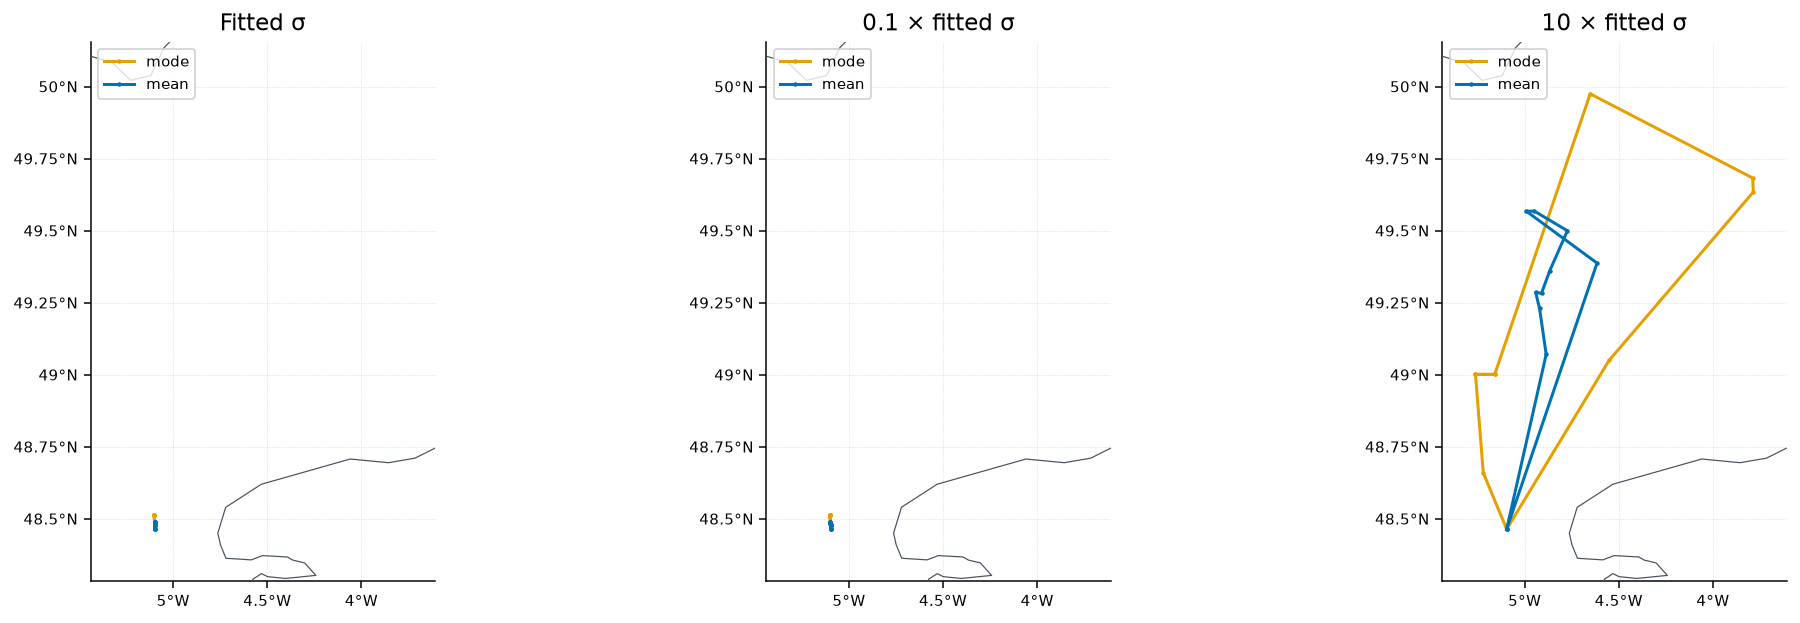

In [81]:
from pangeo_fish.helpers import decode_trajectories

traj_list = [
    decode_trajectories(
        target_root=f"{fit_root}/{subfolder}",
        storage_options=storage_options,
        track_modes=comparison_track_modes,
        chunks=default_chunk_dims,
        save=True,
    )
    for subfolder in [
        "",
        "hand_sigma0.1",
        "hand_sigma10",
    ]
]

traj_plots = [
    plot_trajectories(
        target_root=f"{fit_root}/{subfolder}",
        track_modes=comparison_track_modes,
        storage_options=storage_options,
        save_html=True,
    ).options(title=f"Model's Folder: {subfolder}")
    for subfolder in [
        "",
        "hand_sigma0.1",
        "hand_sigma10",
    ]
]
(traj_plots[0] + traj_plots[1] + traj_plots[2]).cols(2)

## 付録：バグ報告用の情報（Information for bug reports）

うまく動かないときは、どのソフトウェアを使っていたかを正確に知る必要があります。次のセルを実行し（前のセルでエラーが出ていても、いつでも実行できます）、**出力をすべて**コピーして、エラーメッセージと一緒に [issue](https://github.com/pangeo-fish/pangeo-fish-fra2026/issues) やメールに貼り付けてください。

出力からは、次の 3 つのことがわかります。

- **どの計算環境か：** Jupyter サーバーの起動に使った Docker イメージ（レジストリ、名前、タグ。例：`ghcr.io/pangeo-fish/pangeo-fish-notebook:2026.11.2`）。タグの末尾は、イメージの作成に使った Pangeo-Fish のコミットです。
- **どの Pangeo-Fish のコードか：** そのイメージにインストールされている Pangeo-Fish のソースの Git リポジトリとコミット。
- **どのノートブックか：** このワークショップのリポジトリのコミットと、ノートブックを変更したかどうか。

In [82]:
# バグ報告用のソフトウェア情報：出力をすべてコピーして報告に貼り付けてください。
import os
import platform
import shutil
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version


def run(*cmd):
    try:
        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        return result.stdout.strip()
    except Exception as err:
        return f"unavailable ({type(err).__name__})"


def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


git = shutil.which("git", path=os.path.join(sys.prefix, "bin")) or "git"
fish_src = os.environ.get("PANGEO_FISH_SRC", "/srv/pangeo-fish")

print(
    "Docker image       :",
    os.environ.get("JUPYTER_IMAGE", "unknown (not set by the hub)"),
)
print(
    "JupyterHub         :",
    os.environ.get(
        "JUPYTERHUB_SERVICE_URL", os.environ.get("JUPYTERHUB_API_URL", "unknown")
    ),
)
print("Pangeo-Fish version:", pkg_version("pangeo-fish"))
print("Pangeo-Fish source :", run(git, "-C", fish_src, "remote", "get-url", "origin"))
print(
    "Pangeo-Fish commit :",
    run(git, "-C", fish_src, "log", "-1", "--format=%H (%cs) %s"),
)
print("Notebook repository:", run(git, "remote", "get-url", "origin"))
print("Notebook commit    :", run(git, "log", "-1", "--format=%H (%cs) %s"))
print("Notebook changes   :", run(git, "status", "--short", ".") or "none")
print("Python             :", sys.version.split()[0], "on", platform.platform())
for name in ["xarray", "dask", "numpy", "xdggs", "healpix-geo", "copernicusmarine"]:
    print(f"{name:19}:", pkg_version(name))